In [1]:
!pip install numpy
!pip install seaborn
!pip install numpy


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip


In [2]:
!pip install pandas


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import roc_auc_score

In [4]:
df_patient = pd.read_csv('patient.csv')

In [5]:
print("Rows:", df_patient.shape[0])
print("Columns:", df_patient.shape[1])

Rows: 200859
Columns: 29


In [6]:
print(df_patient.columns.tolist())

['patientunitstayid', 'patienthealthsystemstayid', 'gender', 'age', 'ethnicity', 'hospitalid', 'wardid', 'apacheadmissiondx', 'admissionheight', 'hospitaladmittime24', 'hospitaladmitoffset', 'hospitaladmitsource', 'hospitaldischargeyear', 'hospitaldischargetime24', 'hospitaldischargeoffset', 'hospitaldischargelocation', 'hospitaldischargestatus', 'unittype', 'unitadmittime24', 'unitadmitsource', 'unitvisitnumber', 'unitstaytype', 'admissionweight', 'dischargeweight', 'unitdischargetime24', 'unitdischargeoffset', 'unitdischargelocation', 'unitdischargestatus', 'uniquepid']


In [7]:
print(df_patient.dtypes)

patientunitstayid              int64
patienthealthsystemstayid      int64
gender                           str
age                              str
ethnicity                        str
hospitalid                     int64
wardid                         int64
apacheadmissiondx                str
admissionheight              float64
hospitaladmittime24              str
hospitaladmitoffset            int64
hospitaladmitsource              str
hospitaldischargeyear          int64
hospitaldischargetime24          str
hospitaldischargeoffset        int64
hospitaldischargelocation        str
hospitaldischargestatus          str
unittype                         str
unitadmittime24                  str
unitadmitsource                  str
unitvisitnumber                int64
unitstaytype                     str
admissionweight              float64
dischargeweight              float64
unitdischargetime24              str
unitdischargeoffset            int64
unitdischargelocation            str
u

df_patient.info()

Missing Values Analysis

In [7]:
missing = df_patient.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

dischargeweight              90937
hospitaladmitsource          49464
apacheadmissiondx            22996
admissionweight              16718
admissionheight               4215
ethnicity                     2290
hospitaldischargelocation     2033
hospitaldischargestatus       1751
unitadmitsource               1090
unitdischargelocation          334
gender                         134
age                             95
unitdischargestatus             34
dtype: int64


In [9]:
#Missing Percentage

In [8]:
missing_pct = (
    df_patient.isnull().mean() * 100
).sort_values(ascending=False)

print(missing_pct[missing_pct > 0])

dischargeweight              45.274048
hospitaladmitsource          24.626230
apacheadmissiondx            11.448827
admissionweight               8.323252
admissionheight               2.098487
ethnicity                     1.140103
hospitaldischargelocation     1.012153
hospitaldischargestatus       0.871756
unitadmitsource               0.542669
unitdischargelocation         0.166286
gender                        0.066713
age                           0.047297
unitdischargestatus           0.016927
dtype: float64


In [9]:
df_patient = df_patient.drop(
    columns=['dischargeweight']
)

Target Distribution

In [10]:
# ICU Mortality

print(
    df_patient['unitdischargestatus']
    .value_counts()
)

unitdischargestatus
Alive      189918
Expired     10907
Name: count, dtype: int64


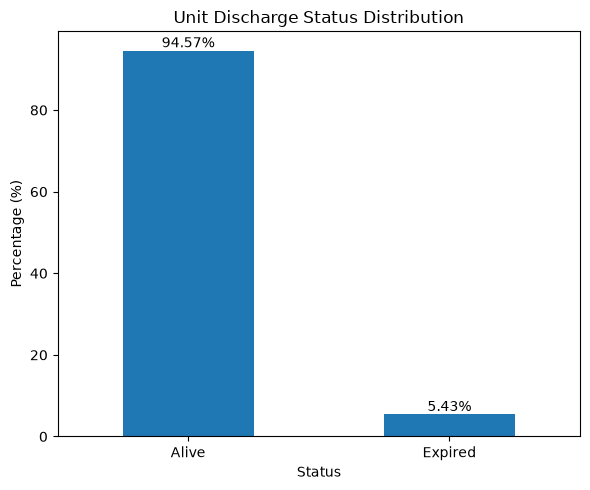

In [11]:
unit_pct = (
    df_patient['unitdischargestatus']
    .value_counts(normalize=True)
    * 100
)

plt.figure(figsize=(6,5))
ax = unit_pct.plot(kind='bar')

plt.title('Unit Discharge Status Distribution')
plt.xlabel('Status')
plt.ylabel('Percentage (%)')

# Make x-axis labels horizontal
plt.xticks(rotation=0)

# Add percentage labels above bars
for i, v in enumerate(unit_pct):
    ax.text(
        i,
        v,
        f'{v:.2f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

In [12]:
# Hospital Discharge Status

print(
    df_patient['hospitaldischargestatus']
    .value_counts()
)

hospitaldischargestatus
Alive      181104
Expired     18004
Name: count, dtype: int64


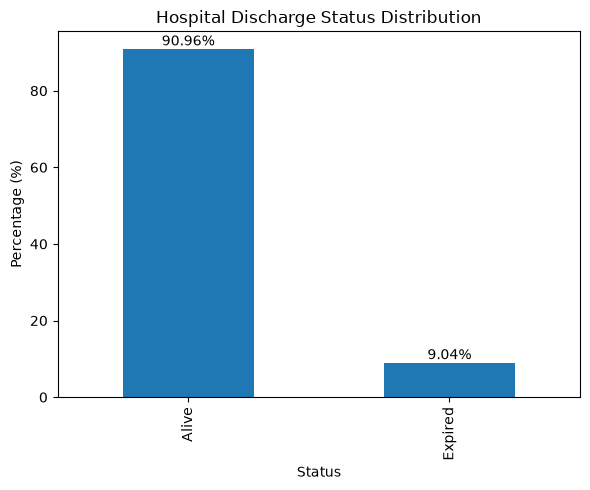

In [13]:
import matplotlib.pyplot as plt

# Hospital discharge status
hospital_pct = (
    df_patient['hospitaldischargestatus']
    .value_counts(normalize=True)
    * 100
)

plt.figure(figsize=(6,5))
ax = hospital_pct.plot(kind='bar')

plt.title('Hospital Discharge Status Distribution')
plt.xlabel('Status')
plt.ylabel('Percentage (%)')

for i, v in enumerate(hospital_pct):
    ax.text(i, v, f'{v:.2f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

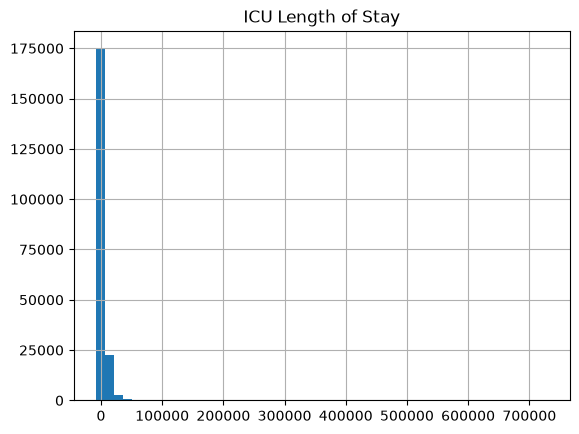

count    200859.000000
mean          2.679258
std           4.330865
min          -5.338194
25%           0.818750
50%           1.573611
75%           2.971528
max         506.372222
Name: unitdischargeoffset, dtype: float64

In [14]:
# ICU Length of Stay

df_patient['unitdischargeoffset'].hist(
    bins=50
)

plt.title('ICU Length of Stay')
plt.show()

los_days = (
    df_patient['unitdischargeoffset']
    / 1440
)

los_days.describe()

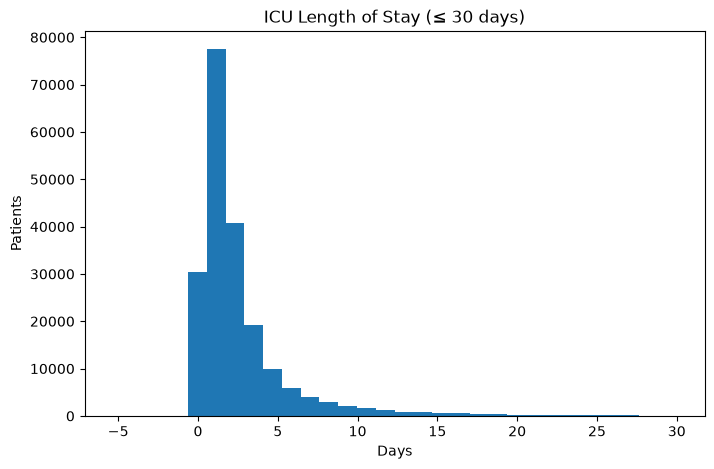

In [15]:
los_days = df_patient['unitdischargeoffset'] / 1440

plt.figure(figsize=(8,5))
plt.hist(los_days[los_days <= 30], bins=30)

plt.title('ICU Length of Stay (≤ 30 days)')
plt.xlabel('Days')
plt.ylabel('Patients')

plt.show()

In [16]:
print(los_days.min())
print((los_days < 0).sum())

-5.3381944444444445
2


In [17]:
df_patient[df_patient['unitdischargeoffset'] < 0][
    ['patientunitstayid', 'hospitalid', 'unitdischargeoffset']
]

,patientunitstayid,hospitalid,unitdischargeoffset
17672,306391,79,-158
79804,1143353,208,-7687


In [18]:
# Remove all records with negative unitdischargeoffset

df_patient = df_patient[df_patient['unitdischargeoffset'] >= 0].reset_index(drop=True)

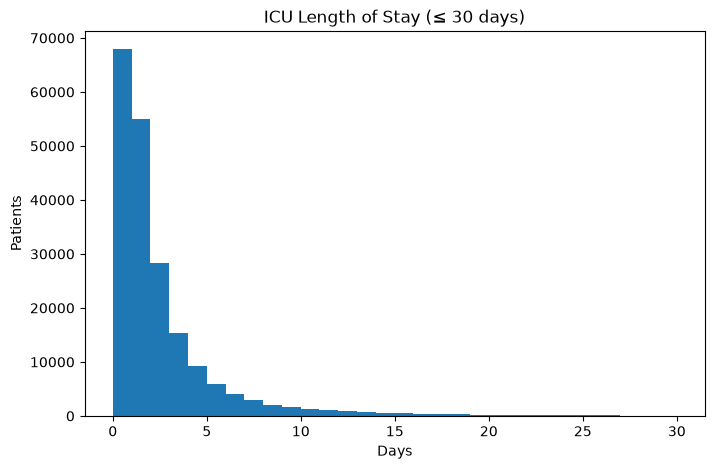

In [19]:
los_days = df_patient['unitdischargeoffset'] / 1440

plt.figure(figsize=(8,5))
plt.hist(los_days[los_days <= 30], bins=30)

plt.title('ICU Length of Stay (≤ 30 days)')
plt.xlabel('Days')
plt.ylabel('Patients')

plt.show()

Hospital Distribution

In [20]:
print(
    df_patient['hospitalid']
    .nunique()
)

208


In [21]:
df_patient['hospitalid'] \
    .value_counts() \
    .head(20)

hospitalid
73     7059
167    6092
264    5237
420    4679
176    4328
338    4277
243    4243
199    4240
458    3701
443    3656
208    3649
300    3617
188    3601
252    3371
411    3199
165    3053
122    2941
148    2881
171    2807
281    2531
Name: count, dtype: int64

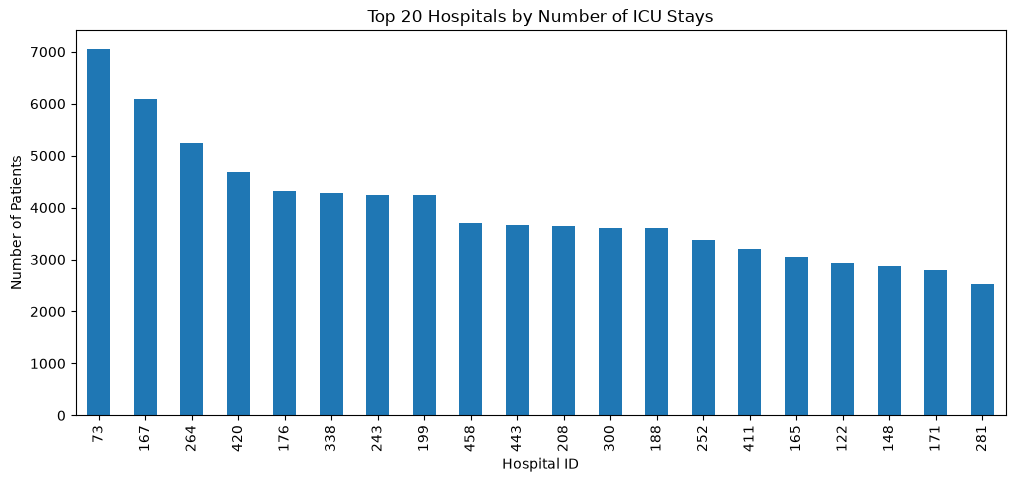

In [22]:
import matplotlib.pyplot as plt

hospital_counts = (
    df_patient['hospitalid']
    .value_counts()
)

plt.figure(figsize=(12,5))

hospital_counts.head(20).plot(kind='bar')

plt.title('Top 20 Hospitals by Number of ICU Stays')
plt.xlabel('Hospital ID')
plt.ylabel('Number of Patients')

plt.show()

Correlation Matrix

+1 → perfect positive relationship

0 → no linear relationship

−1 → perfect negative relationship

In [23]:
cols_to_drop = [
    'patientunitstayid',
    'patienthealthsystemstayid',
    'hospitalid',
    'wardid'
]

numeric_cols = df_patient.select_dtypes(include='number')

corr = numeric_cols.drop(
    columns=cols_to_drop,
    errors='ignore'
).corr()

print(corr)

                         admissionheight  hospitaladmitoffset  \
admissionheight                 1.000000            -0.005952   
hospitaladmitoffset            -0.005952             1.000000   
hospitaldischargeyear          -0.011333            -0.007284   
hospitaldischargeoffset         0.006370            -0.136714   
unitvisitnumber                 0.004269            -0.418231   
admissionweight                 0.290197            -0.005580   
unitdischargeoffset             0.010104            -0.050576   

                         hospitaldischargeyear  hospitaldischargeoffset  \
admissionheight                      -0.011333                 0.006370   
hospitaladmitoffset                  -0.007284                -0.136714   
hospitaldischargeyear                 1.000000                -0.005578   
hospitaldischargeoffset              -0.005578                 1.000000   
unitvisitnumber                       0.010596                 0.056545   
admissionweight              

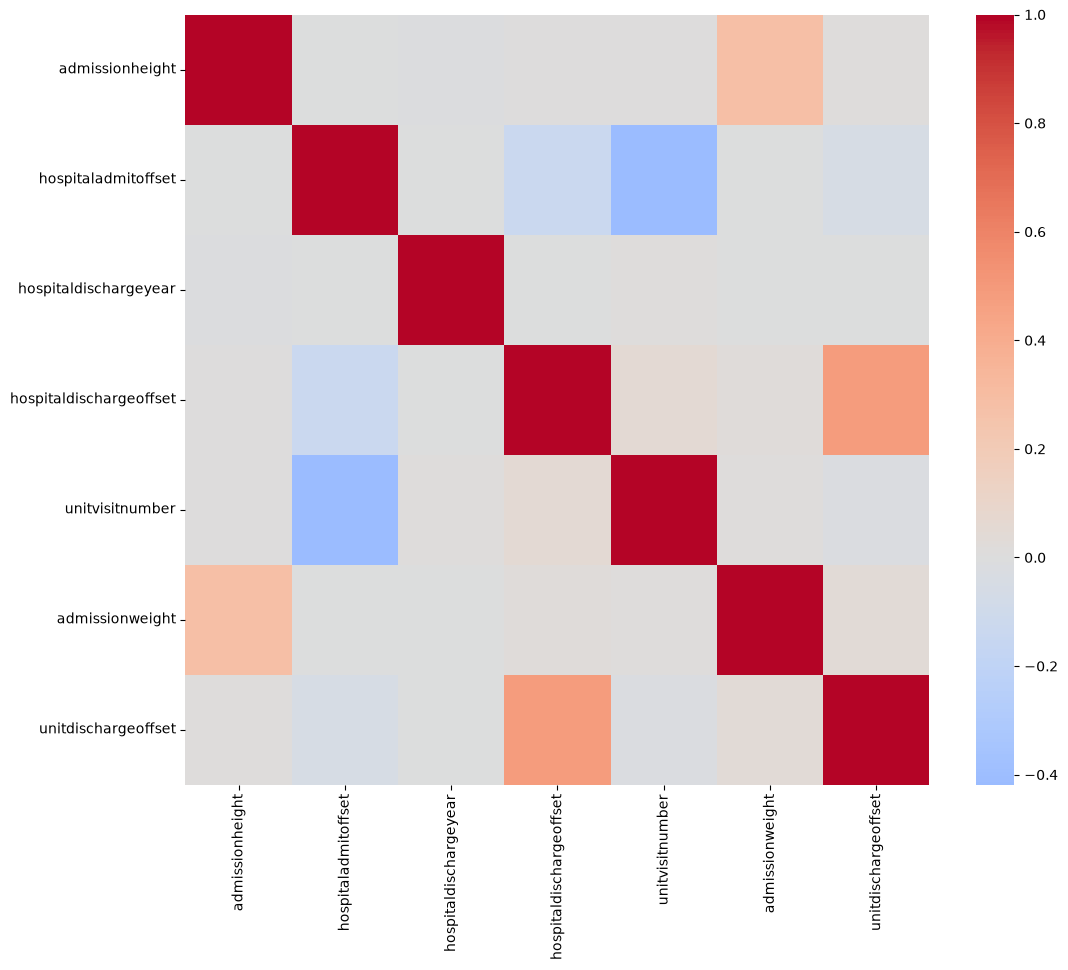

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,10))

sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0
)

plt.show()

In [25]:
print(
    "Hospitals:",
    df_patient['hospitalid'].nunique()
)

print(
    "ICU types:",
    df_patient['unittype'].value_counts()
)

# print(
#     "Regions:",
#     df_patient['region'].value_counts()
# )

Hospitals: 208
ICU types: unittype
Med-Surg ICU    113221
MICU             17464
CCU-CTICU        15290
Neuro ICU        14451
Cardiac ICU      12467
SICU             12181
CSICU             9625
CTICU             6158
Name: count, dtype: int64


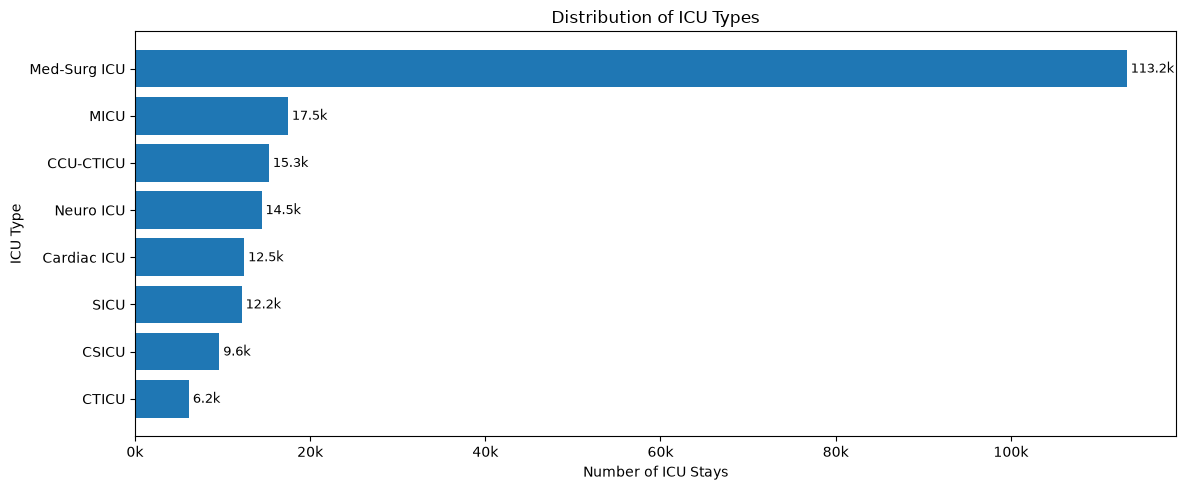

In [26]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

icu_counts = (
    df_patient['unittype']
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(12, 5))

plt.barh(
    icu_counts.index,
    icu_counts.values
)

plt.xlabel("Number of ICU Stays")
plt.ylabel("ICU Type")
plt.title("Distribution of ICU Types")

# Format x-axis ticks as 20k, 40k, ...
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'{int(x/1000)}k')
)

# Add value labels as 113.2k, 17.5k, ...
for i, value in enumerate(icu_counts.values):
    plt.text(
        value,
        i,
        f" {value/1000:.1f}k",
        va='center',
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [29]:
# df_patient = df_patient.drop(
#     columns=['dischargeweight']
# )

Separate numerical and categorical columns

In [27]:
num_cols = df_patient.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df_patient.select_dtypes(include=['object']).columns

print("Numerical:", len(num_cols))
print("Categorical:", len(cat_cols))

Numerical: 11
Categorical: 17


/tmp/ipykernel_599357/2258273544.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_patient.select_dtypes(include=['object']).columns


In [28]:
cat_cols = df_patient.select_dtypes(
    include=['object', 'string', 'category']
).columns

print("Categorical columns:")
print(cat_cols.tolist())

print("\nNumber of categorical columns:", len(cat_cols))

Categorical columns:
['gender', 'age', 'ethnicity', 'apacheadmissiondx', 'hospitaladmittime24', 'hospitaladmitsource', 'hospitaldischargetime24', 'hospitaldischargelocation', 'hospitaldischargestatus', 'unittype', 'unitadmittime24', 'unitadmitsource', 'unitstaytype', 'unitdischargetime24', 'unitdischargelocation', 'unitdischargestatus', 'uniquepid']

Number of categorical columns: 17


In [29]:
num_cols = df_patient.select_dtypes(
    include=['number']
).columns

print("Numerical columns:")
print(num_cols.tolist())

print("\nNumber of numerical columns:", len(num_cols))

Numerical columns:
['patientunitstayid', 'patienthealthsystemstayid', 'hospitalid', 'wardid', 'admissionheight', 'hospitaladmitoffset', 'hospitaldischargeyear', 'hospitaldischargeoffset', 'unitvisitnumber', 'admissionweight', 'unitdischargeoffset']

Number of numerical columns: 11


Numerical columns → Median imputation

In [30]:
#df_patient['age'] = df_patient['age'].replace('> 89', '90')

df_patient['age'] = df_patient['age'].replace('> 89', '90')

df_patient['age'] = pd.to_numeric(
    df_patient['age'],
    errors='coerce'
)

In [31]:
df_patient['admissionweight'] = (
    df_patient['admissionweight']
    .fillna(df_patient['admissionweight'].median())
)

df_patient['admissionheight'] = (
    df_patient['admissionheight']
    .fillna(df_patient['admissionheight'].median())
)

df_patient['age'] = (
    df_patient['age']
    .fillna(df_patient['age'].median())
)

In [32]:
print(df_patient['age'].dtype)

print(df_patient['age'].head(20))

print(df_patient['age'].unique()[:20])

float64
0     70.0
1     52.0
2     52.0
3     68.0
4     71.0
5     71.0
6     77.0
7     25.0
8     82.0
9     90.0
10    81.0
11    59.0
12    43.0
13    19.0
14    19.0
15    67.0
16    73.0
17    59.0
18    63.0
19    61.0
Name: age, dtype: float64
[70. 52. 68. 71. 77. 25. 82. 90. 81. 59. 43. 19. 67. 73. 63. 61. 45. 76.
 50. 72.]


In [33]:
df_patient['uniquepid'].nunique()


139367

In [34]:
df_patient['patienthealthsystemstayid'].nunique()

166353

In [35]:
df_patient.columns.tolist()

['patientunitstayid',
 'patienthealthsystemstayid',
 'gender',
 'age',
 'ethnicity',
 'hospitalid',
 'wardid',
 'apacheadmissiondx',
 'admissionheight',
 'hospitaladmittime24',
 'hospitaladmitoffset',
 'hospitaladmitsource',
 'hospitaldischargeyear',
 'hospitaldischargetime24',
 'hospitaldischargeoffset',
 'hospitaldischargelocation',
 'hospitaldischargestatus',
 'unittype',
 'unitadmittime24',
 'unitadmitsource',
 'unitvisitnumber',
 'unitstaytype',
 'admissionweight',
 'unitdischargetime24',
 'unitdischargeoffset',
 'unitdischargelocation',
 'unitdischargestatus',
 'uniquepid']

In [36]:
icu_per_patient = (
    df_patient.groupby('uniquepid')['patientunitstayid']
              .nunique()
)

icu_per_patient.value_counts().sort_index()

patientunitstayid
1     100885
2      26553
3       6612
4       2900
5       1093
6        603
7        305
8        153
9         88
10        66
11        28
12        24
13        10
14        15
15         7
16         4
17         4
18         2
19         4
20         1
21         3
22         2
24         3
26         2
Name: count, dtype: int64

In [37]:
icu_per_patient = (
    df_patient.groupby('uniquepid')['patientunitstayid']
              .nunique()
              .reset_index()
)

icu_per_patient.columns = [
    'uniquepid',
    'icu_stay_count'
]

icu_per_patient.head(20)

,uniquepid,icu_stay_count
0,002-10009,1
1,002-10018,1
2,002-10034,1
3,002-10050,3
4,002-10052,1
5,002-10063,1
6,002-10066,1
7,002-10067,1
8,002-1007,1
9,002-10076,2


In [38]:
top_10_patients = (
    icu_per_patient
    .sort_values('icu_stay_count', ascending=False)
    .head(10)
)

print(top_10_patients)

        uniquepid  icu_stay_count
82418  021-120471              26
86164  021-239346              26
59884   015-76326              24
24560  006-181132              24
19724  006-100497              24
32712   006-88120              22
49322    011-1993              22
22822  006-151852              21
29870   006-40127              21
8409    002-77978              21


Does having more ICU stays make a patient easier to identify as a training member?

Missing Value Analysis

In [39]:
missing_values = pd.DataFrame({
    'missing_count': df_patient.isnull().sum(),
    'missing_percentage': (
        df_patient.isnull().sum() / len(df_patient) * 100
    ).round(2),
    'dtype': df_patient.dtypes
})

missing_values = missing_values.sort_values(
    'missing_percentage',
    ascending=False
)

missing_values

,missing_count,missing_percentage,dtype
hospitaladmitsource,49463,24.63,str
apacheadmissiondx,22996,11.45,str
ethnicity,2290,1.14,str
hospitaldischargelocation,2033,1.01,str
hospitaldischargestatus,1751,0.87,str
unitadmitsource,1090,0.54,str
unitdischargelocation,332,0.17,str
gender,134,0.07,str
unitdischargestatus,33,0.02,str
age,0,0.00,float64


# Dataset Preprocessing

admissionweight	8.32%	Median imputation

admissionheight	2.10%	Median imputation

In [40]:
df_patient['admissionweight'] = (
    df_patient['admissionweight']
    .fillna(df_patient['admissionweight'].median())
)

df_patient['admissionheight'] = (
    df_patient['admissionheight']
    .fillna(df_patient['admissionheight'].median())
)

In [41]:
categorical_cols = [
    'hospitaladmitsource',
    'apacheadmissiondx',
    'ethnicity',
    'unitadmitsource',
    'gender'
]

for col in categorical_cols:
    df_patient[col] = df_patient[col].fillna('Unknown')

In [42]:
df_patient['age'].value_counts(dropna=False).head(20)

age
90.0    7081
67.0    5078
68.0    4825
72.0    4804
71.0    4764
65.0    4744
66.0    4677
70.0    4571
63.0    4460
62.0    4355
73.0    4333
64.0    4318
69.0    4301
75.0    4280
60.0    4217
61.0    4197
76.0    4169
74.0    4126
77.0    4110
59.0    4068
Name: count, dtype: int64

In [43]:
df_patient['age'] = (
    df_patient['age']
    .replace('> 89', 90)
)

In [44]:
df_patient['apacheadmissiondx'].nunique()

393

Most Common Diagnosis

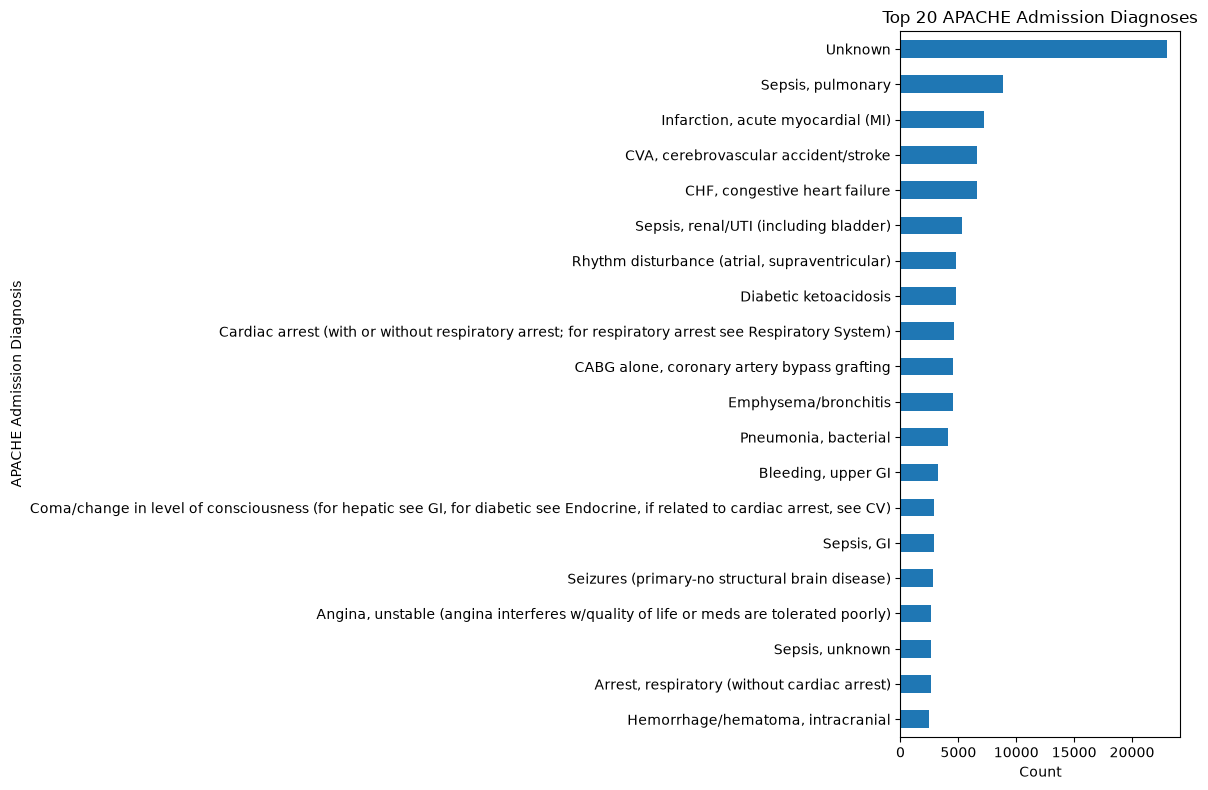

In [45]:
top_dx = (
    df_patient['apacheadmissiondx']
    .value_counts()
    .head(20)
)

import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))
top_dx.sort_values().plot(kind='barh')

plt.xlabel('Count')
plt.ylabel('APACHE Admission Diagnosis')
plt.title('Top 20 APACHE Admission Diagnoses')

plt.tight_layout()
plt.show()

In [46]:
top_dx = (
    df_patient['apacheadmissiondx']
    .value_counts()
    .head(20)
    .reset_index()
)

top_dx.columns = ['Diagnosis', 'Count']

print(top_dx)

                                            Diagnosis  Count
0                                             Unknown  22996
1                                   Sepsis, pulmonary   8862
2                   Infarction, acute myocardial (MI)   7227
3                CVA, cerebrovascular accident/stroke   6647
4                       CHF, congestive heart failure   6617
5               Sepsis, renal/UTI (including bladder)   5273
6       Rhythm disturbance (atrial, supraventricular)   4827
7                               Diabetic ketoacidosis   4825
8   Cardiac arrest (with or without respiratory ar...   4580
9         CABG alone, coronary artery bypass grafting   4543
10                               Emphysema/bronchitis   4494
11                               Pneumonia, bacterial   4101
12                                 Bleeding, upper GI   3238
13  Coma/change in level of consciousness (for hep...   2902
14                                         Sepsis, GI   2881
15     Seizures (primary

# Mortality rate per diagnosis.

In [47]:
df_patient['target'] = (
    df_patient['unitdischargestatus']
      .eq('Expired')
      .astype(int)
)

In [48]:
mortality_by_dx = (
    df_patient
    .groupby('apacheadmissiondx')['target']
    .agg(['count', 'mean'])
    .sort_values('count', ascending=False)
)

mortality_by_dx.head(20)

,count,mean
apacheadmissiondx,,
Unknown,22996,0.030092
"Sepsis, pulmonary",8862,0.120515
"Infarction, acute myocardial (MI)",7227,0.030580
"CVA, cerebrovascular accident/stroke",6647,0.049797
"CHF, congestive heart failure",6617,0.053952
"Sepsis, renal/UTI (including bladder)",5273,0.062773
"Rhythm disturbance (atrial, supraventricular)",4827,0.029004
Diabetic ketoacidosis,4825,0.003523
Cardiac arrest (with or without respiratory arrest; for respiratory arrest see Respiratory System),4580,0.414847


In [49]:
mortality_by_dx = (
    df_patient
    .groupby('apacheadmissiondx')['target']
    .agg(['count', 'mean'])
    .reset_index()
)

mortality_by_dx['mortality_percent'] = (
    mortality_by_dx['mean'] * 100
).round(2)

mortality_by_dx = mortality_by_dx[
    mortality_by_dx['count'] >= 100
]

mortality_by_dx.sort_values(
    'mortality_percent',
    ascending=False
).head(20)

,apacheadmissiondx,count,mean,mortality_percent
89,Cardiac arrest (with or without respiratory ar...,4580,0.414847,41.48
337,"Shock, cardiogenic",550,0.223636,22.36
76,"Cancer, lung",364,0.173077,17.31
210,"Hemorrhage/hematoma-intracranial, surgery for",180,0.166667,16.67
26,"Aneurysm, thoracic aortic; with dissection",138,0.166667,16.67
175,"GI vascular ischemia, surgery for (resection)",211,0.156398,15.64
330,"Sepsis, GI",2881,0.135717,13.57
213,"Hepatic failure, acute",378,0.129630,12.96
37,"Arrest, respiratory (without cardiac arrest)",2599,0.126972,12.70
209,"Hemorrhage/hematoma, intracranial",2450,0.122449,12.24


In [50]:
# Age values
df_patient['age'].value_counts(dropna=False).head(20)

# Gender distribution
df_patient['gender'].value_counts(dropna=False)

# Ethnicity distribution
df_patient['ethnicity'].value_counts(dropna=False)

# ICU mortality distribution
df_patient['unitdischargestatus'].value_counts(dropna=False)

unitdischargestatus
Alive      189917
Expired     10907
NaN            33
Name: count, dtype: int64

In [51]:
df_patient = df_patient.dropna(
    subset=['unitdischargestatus']
)

In [52]:
# Age values
df_patient['age'].value_counts(dropna=False).head(20)

# Gender distribution
df_patient['gender'].value_counts(dropna=False)

# Ethnicity distribution
df_patient['ethnicity'].value_counts(dropna=False)

# ICU mortality distribution
df_patient['unitdischargestatus'].value_counts(dropna=False)

unitdischargestatus
Alive      189917
Expired     10907
Name: count, dtype: int64

In [53]:
# Create Target Variable

df_patient['target'] = (
    df_patient['unitdischargestatus']
      .eq('Expired')
      .astype(int)
)

In [54]:
df_patient['target'].value_counts()

target
0    189917
1     10907
Name: count, dtype: int64

In [55]:
# Remove rows with missing target

df_patient = df_patient.dropna(subset=['unitdischargestatus'])

df_patient['target'] = (
    df_patient['unitdischargestatus']
      .eq('Expired')
      .astype(int)
)

In [56]:
df_patient['target'].value_counts()

target
0    189917
1     10907
Name: count, dtype: int64

In [57]:
# Keep identifiers separately:

meta = df_patient[['uniquepid', 'patientunitstayid']].copy()

In [58]:
# Select features:

features = [
    'gender',
    'age',
    'ethnicity',
    'apacheadmissiondx',
    'admissionheight',
    'admissionweight',
    'hospitaladmitoffset',
    'hospitaladmitsource',
    'unittype',
    'unitadmitsource',
    'unitvisitnumber',
    'unitstaytype'
]

X = df_patient[features].copy()
y = df_patient['target']

In [59]:
# handle missing if any

num_cols = [
    'admissionheight',
    'admissionweight',
    'hospitaladmitoffset',
    'unitvisitnumber'
]

for col in num_cols:
    X[col] = X[col].fillna(X[col].median())

# Categorical

cat_cols = [
    'gender',
    'age',
    'ethnicity',
    'apacheadmissiondx',
    'hospitaladmitsource',
    'unittype',
    'unitadmitsource',
    'unitstaytype'
]

for col in cat_cols:
    X[col] = X[col].fillna('Unknown')    

In [60]:
# Handle age if necessary:
X['age'] = X['age'].replace('> 89', '90')
X['age'] = pd.to_numeric(X['age'], errors='coerce')
X['age'] = X['age'].fillna(X['age'].median())

Split by patient (important)

In [61]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(
        X,
        y,
        groups=df_patient['uniquepid']
    )
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

Encode categorical variables

In [62]:
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

X_train, X_test = X_train.align(
    X_test,
    join='left',
    axis=1,
    fill_value=0
)

Apply SMOTE only on training data

In [63]:
from imblearn.over_sampling import SMOTE

print("Before SMOTE:")
print(y_train.value_counts())

smote = SMOTE(
    sampling_strategy='auto',
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
target
0    151939
1      8708
Name: count, dtype: int64

After SMOTE:
target
1    151939
0    151939
Name: count, dtype: int64


Verify class balance visually

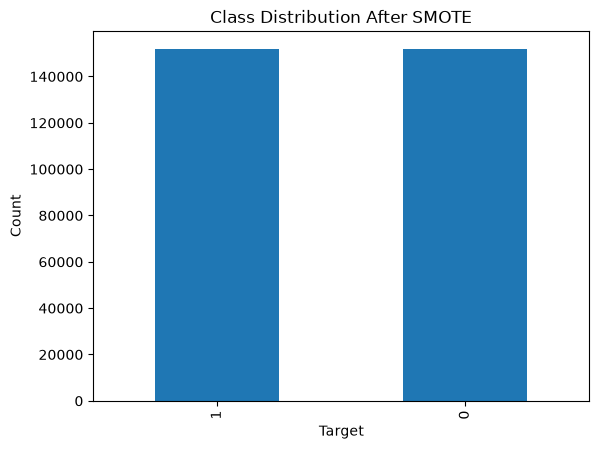

In [64]:
import matplotlib.pyplot as plt

y_train_smote.value_counts().plot(
    kind='bar'
)

plt.title('Class Distribution After SMOTE')
plt.xlabel('Target')
plt.ylabel('Count')
plt.show()

# 1.1 Applying MLP Model

Applying on SMOTE Dateset

In [65]:
# Scale the SMOTE data

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_smote_scaled = scaler.fit_transform(
    X_train_smote
)

X_test_scaled = scaler.transform(
    X_test
)

In [66]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    batch_size=256,
    learning_rate='adaptive',
    max_iter=100,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)

mlp.fit(
    X_train_smote_scaled,
    y_train_smote
)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(128, ...)"
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",256
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'adaptive'
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",100
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by at least``tol`` for ``n_iter_no_change`` consecutive epochs. The split isstratified, except in a multilabel setting.If early stopping is False, then the training stops when the trainingloss does not improve by more than ``tol`` for ``n_iter_no_change``consecutive passes over the training set.Only effective when solver='sgd' or 'adam'.",True
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating th

In [67]:
# Predicted probabilities for the positive class
y_prob = mlp.predict_proba(X_test_scaled)[:, 1]

In [68]:
precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_prob
)

f1_scores = 2 * precision * recall / (precision + recall + 1e-10)

best_idx = np.argmax(f1_scores)

print("Best threshold:", thresholds[best_idx])
print("Best F1:", f1_scores[best_idx])
print("Precision:", precision[best_idx])
print("Recall:", recall[best_idx])

Best threshold: 0.16771298787497418
Best F1: 0.2559706061966956
Precision: 0.23222222222222222
Recall: 0.28512960436562074


In [69]:
threshold = 0.167

y_pred_mlp = (y_prob >= threshold).astype(int)

print(
    classification_report(
        y_test,
        y_pred_mlp,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9581    0.9450    0.9515     37978
           1     0.2313    0.2856    0.2556      2199

    accuracy                         0.9090     40177
   macro avg     0.5947    0.6153    0.6036     40177
weighted avg     0.9183    0.9090    0.9134     40177



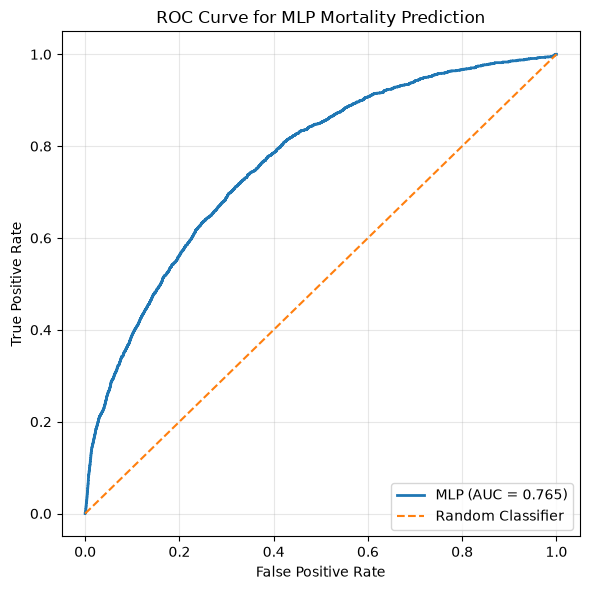

MLP AUC: 0.765


In [70]:
# Compute ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

# Compute AUC
utility_auc_mlp = roc_auc_score(
    y_test,
    y_prob
)

# Plot ROC curve
plt.figure(figsize=(6, 6))

plt.plot(
    fpr,
    tpr,
    label=f"MLP (AUC = {utility_auc_mlp:.3f})",
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for MLP Mortality Prediction")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(
    f"MLP AUC: {utility_auc_mlp:.3f}"
)

# 1.2.1 Loss Based Membership Inference Attack on MLP (SMOTE-Expanded Training Set)

In [131]:
# Compute per-sample loss (MLP)

eps = 1e-15

# Members
train_prob_mlp = mlp.predict_proba(
    X_train_smote_scaled
)

train_true_prob_mlp = (
    train_prob_mlp[
        np.arange(len(y_train_smote)),
        y_train_smote
    ]
)

train_loss_mlp = -np.log(
    np.clip(
        train_true_prob_mlp,
        eps,
        1 - eps
    )
)

# Non-members
test_prob_mlp = mlp.predict_proba(
    X_test_scaled
)

test_true_prob_mlp = (
    test_prob_mlp[
        np.arange(len(y_test)),
        y_test
    ]
)

test_loss_mlp = -np.log(
    np.clip(
        test_true_prob_mlp,
        eps,
        1 - eps
    )
)

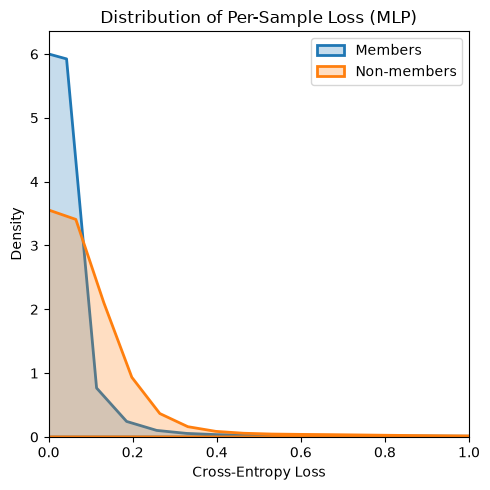

In [132]:
plt.figure(figsize=(5,5))

sns.kdeplot(
    train_loss_mlp,
    label="Members",
    fill=True,
    linewidth=2
)

sns.kdeplot(
    test_loss_mlp,
    label="Non-members",
    fill=True,
    linewidth=2
)

plt.xlim(0, 1)      # or 0.8 after checking your data

plt.xlabel("Cross-Entropy Loss")
plt.ylabel("Density")
plt.title("Distribution of Per-Sample Loss (MLP)")
plt.legend()

plt.tight_layout()
plt.show()

In [133]:
attack_scores_mlp = np.concatenate([
    -train_loss_mlp,
    -test_loss_mlp
])

attack_labels_mlp = np.concatenate([
    np.ones(len(train_loss_mlp)),
    np.zeros(len(test_loss_mlp))
])

mia_auc = roc_auc_score(
    attack_labels_mlp,
    attack_scores_mlp
)

print(
     f"Loss Based Membership Inference Attack AUC MLP (On Smote Data): {mia_auc:.3f}"
)

Loss Based Membership Inference Attack AUC MLP (On Smote Data): 0.730


# 1.2.2 Loss Based Membership Inference Attack on MLP (Original Training Members Set)

In [135]:
# 1.2 Loss Based Membership Inference Attack on MLP

eps = 1e-15

# --------------------------------------------------------
# Members: ORIGINAL training records only
# --------------------------------------------------------

X_train_scaled_original = scaler.transform(
    X_train
)

train_prob_mlp = mlp.predict_proba(
    X_train_scaled_original
)

train_true_prob_mlp = train_prob_mlp[
    np.arange(len(y_train)),
    y_train
]

train_loss_mlp = -np.log(
    np.clip(
        train_true_prob_mlp,
        eps,
        1 - eps
    )
)

# --------------------------------------------------------
# Non-members: ORIGINAL held-out test records
# --------------------------------------------------------

test_prob_mlp = mlp.predict_proba(
    X_test_scaled
)

test_true_prob_mlp = test_prob_mlp[
    np.arange(len(y_test)),
    y_test
]

test_loss_mlp = -np.log(
    np.clip(
        test_true_prob_mlp,
        eps,
        1 - eps
    )
)

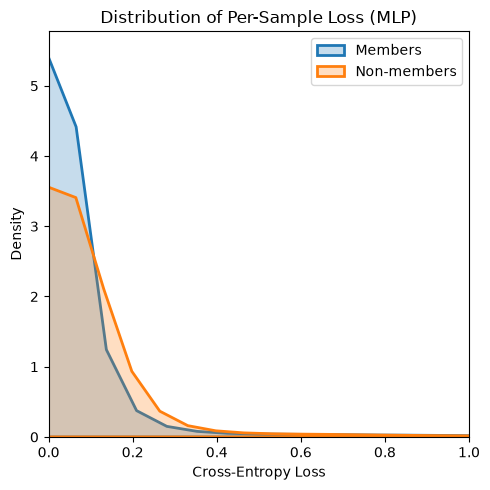

In [136]:
plt.figure(figsize=(5,5))

sns.kdeplot(
    train_loss_mlp,
    label="Members",
    fill=True,
    linewidth=2
)

sns.kdeplot(
    test_loss_mlp,
    label="Non-members",
    fill=True,
    linewidth=2
)

plt.xlim(0, 1)      # or 0.8 after checking your data

plt.xlabel("Cross-Entropy Loss")
plt.ylabel("Density")
plt.title("Distribution of Per-Sample Loss (MLP)")
plt.legend()

plt.tight_layout()
plt.show()

Build attack dataset

Low loss -> likely member

In [137]:
attack_scores_mlp = np.concatenate([
    -train_loss_mlp,
    -test_loss_mlp
])

attack_labels_mlp = np.concatenate([
    np.ones(len(train_loss_mlp)),
    np.zeros(len(test_loss_mlp))
])

mia_auc = roc_auc_score(
    attack_labels_mlp,
    attack_scores_mlp
)

print(
     f"Loss Based Membership Inference Attack AUC (MLP): {mia_auc:.3f}"
)

Loss Based Membership Inference Attack AUC (MLP): 0.508


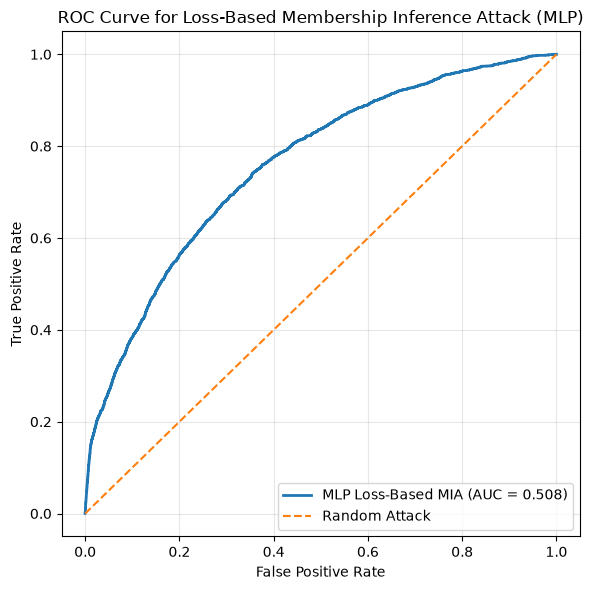

In [138]:
fpr_mlp, tpr_mlp, thresholds_mlp = roc_curve(
    attack_labels_mlp,
    attack_scores_mlp
)

mia_auc_mlp = roc_auc_score(
    attack_labels_mlp,
    attack_scores_mlp
)

# Plot ROC curve
plt.figure(figsize=(6, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"MLP Loss-Based MIA (AUC = {mia_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Attack"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Loss-Based Membership Inference Attack (MLP)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Classification Report of Loss based MIA on MLP

In [75]:
precision, recall, thresholds = precision_recall_curve(
    attack_labels_mlp,
    attack_scores_mlp
)

f1_scores = (
    2 * precision * recall /
    (precision + recall + 1e-10)
)

best_idx = np.argmax(f1_scores)

best_threshold_mlp = thresholds[best_idx]

print(f"Best Attack Threshold: {best_threshold_mlp:.4f}")

# Generate attack predictions

attack_pred_mlp = (
    attack_scores_mlp >= best_threshold_mlp
).astype(int)

# Print the classification report

print(
    classification_report(
        attack_labels_mlp,
        attack_pred_mlp,
        digits=4
    )
)

Best Attack Threshold: -7.8201
              precision    recall  f1-score   support

         0.0     0.7755    0.0009    0.0019     40177
         1.0     0.8001    0.9999    0.8889    160647

    accuracy                         0.8001    200824
   macro avg     0.7878    0.5004    0.4454    200824
weighted avg     0.7952    0.8001    0.7115    200824



# 1.3 Likehood Ratio Attack (Shadow Model based Attack)

In [322]:
# ============================================================
# LiRA Step 1: Prepare Original Target Samples
# ============================================================

# Transform original training samples using the
# scaler fitted on the SMOTE training data.

X_train_scaled_original = scaler.transform(
    X_train
)

print(
    "Original member samples:",
    X_train_scaled_original.shape
)

print(
    "Original non-member samples:",
    X_test_scaled.shape
)

Original member samples: (160647, 445)
Original non-member samples: (40177, 445)


In [323]:
print(X_train.shape)
print(X_train_smote.shape)

print(y_train.value_counts())
print(y_train_smote.value_counts())

(160647, 445)
(303878, 445)
target
0    151939
1      8708
Name: count, dtype: int64
target
1    151939
0    151939
Name: count, dtype: int64


In [324]:
# ============================================================
# LiRA Step 2: Create Shadow Model 1 Dataset
# ============================================================

from sklearn.model_selection import GroupShuffleSplit

# Patient IDs corresponding to the original training set
train_groups = (
    df_patient.iloc[train_idx]["uniquepid"]
    .reset_index(drop=True)
)

# Patient-wise split for Shadow Model 1
shadow_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=1
)

shadow_train_idx, shadow_test_idx = next(
    shadow_split.split(
        X_train,
        y_train,
        groups=train_groups
    )
)

# Shadow training set (original)
X_shadow_train = X_train.iloc[shadow_train_idx]
y_shadow_train = y_train.iloc[shadow_train_idx]

# Shadow test set (original)
X_shadow_test = X_train.iloc[shadow_test_idx]
y_shadow_test = y_train.iloc[shadow_test_idx]

print("Shadow Train:", X_shadow_train.shape)
print("Shadow Test :", X_shadow_test.shape)

print("\nShadow Train Distribution:")
print(y_shadow_train.value_counts())

print("\nShadow Test Distribution:")
print(y_shadow_test.value_counts())

Shadow Train: (128527, 445)
Shadow Test : (32120, 445)

Shadow Train Distribution:
target
0    121508
1      7019
Name: count, dtype: int64

Shadow Test Distribution:
target
0    30431
1     1689
Name: count, dtype: int64


In [325]:
# ============================================================
# Verify No Patient Overlap
# ============================================================

shadow_train_patients = set(
    train_groups.iloc[shadow_train_idx]
)

shadow_test_patients = set(
    train_groups.iloc[shadow_test_idx]
)

overlap = shadow_train_patients.intersection(
    shadow_test_patients
)

print("Shadow Train Patients :", len(shadow_train_patients))
print("Shadow Test Patients  :", len(shadow_test_patients))
print("Overlapping Patients  :", len(overlap))

if len(overlap) == 0:
    print("No patient overlap detected.")
else:
    print("Patient overlap detected!")

Shadow Train Patients : 89191
Shadow Test Patients  : 22298
Overlapping Patients  : 0
No patient overlap detected.


In [326]:
# ============================================================
# LiRA Step 3: Apply SMOTE to Shadow Training Set
# ============================================================

from imblearn.over_sampling import SMOTE

shadow_smote = SMOTE(
    sampling_strategy="auto",
    random_state=42
)

X_shadow_train_smote, y_shadow_train_smote = (
    shadow_smote.fit_resample(
        X_shadow_train,
        y_shadow_train
    )
)

print("Before SMOTE:")
print(y_shadow_train.value_counts())

print("\nAfter SMOTE:")
print(y_shadow_train_smote.value_counts())

print("\nShadow Train After SMOTE:")
print(X_shadow_train_smote.shape)

Before SMOTE:
target
0    121508
1      7019
Name: count, dtype: int64

After SMOTE:
target
1    121508
0    121508
Name: count, dtype: int64

Shadow Train After SMOTE:
(243016, 445)


In [327]:
# ============================================================
# LiRA Step 4: Standardize Shadow Model Data
# ============================================================

from sklearn.preprocessing import StandardScaler

shadow_scaler = StandardScaler()

# Fit scaler on SMOTE shadow training data
X_shadow_train_smote_scaled = shadow_scaler.fit_transform(
    X_shadow_train_smote
)

# Transform ORIGINAL shadow training data
# (used later for IN confidence scores)
X_shadow_train_scaled_original = shadow_scaler.transform(
    X_shadow_train
)

# Transform ORIGINAL shadow test data
# (used later for OUT confidence scores)
X_shadow_test_scaled = shadow_scaler.transform(
    X_shadow_test
)

print("Shadow Train (SMOTE):",
      X_shadow_train_smote_scaled.shape)

print("Shadow Train (Original):",
      X_shadow_train_scaled_original.shape)

print("Shadow Test:",
      X_shadow_test_scaled.shape)

Shadow Train (SMOTE): (243016, 445)
Shadow Train (Original): (128527, 445)
Shadow Test: (32120, 445)


In [328]:
# ============================================================
# LiRA Step 5: Train Shadow Model 1
# ============================================================

from sklearn.neural_network import MLPClassifier

shadow_mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    batch_size=256,
    learning_rate="adaptive",
    max_iter=100,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=1
)

shadow_mlp.fit(
    X_shadow_train_smote_scaled,
    y_shadow_train_smote
)

print("Shadow Model 1 training completed.")

Shadow Model 1 training completed.


In [329]:
# ============================================================
# LiRA Step 6: Collect IN and OUT Confidence Scores
# ============================================================

# Predict probabilities for ORIGINAL shadow training patients
train_prob_shadow = shadow_mlp.predict_proba(
    X_shadow_train_scaled_original
)

# Predict probabilities for ORIGINAL shadow test patients
test_prob_shadow = shadow_mlp.predict_proba(
    X_shadow_test_scaled
)

# Probability assigned to the true class

train_true_prob_shadow = train_prob_shadow[
    np.arange(len(y_shadow_train)),
    y_shadow_train
]

test_true_prob_shadow = test_prob_shadow[
    np.arange(len(y_shadow_test)),
    y_shadow_test
]

print("Shadow Train Probabilities:", train_true_prob_shadow.shape)
print("Shadow Test Probabilities :", test_true_prob_shadow.shape)

Shadow Train Probabilities: (128527,)
Shadow Test Probabilities : (32120,)


In [330]:
# ============================================================
# LiRA Step 7: Convert Confidence Scores to Logit Scores
# ============================================================

import numpy as np

eps = 1e-15

# Avoid probabilities of exactly 0 or 1
train_true_prob_shadow = np.clip(
    train_true_prob_shadow,
    eps,
    1 - eps
)

test_true_prob_shadow = np.clip(
    test_true_prob_shadow,
    eps,
    1 - eps
)

# Logit transformation
shadow_in_logits = np.log(
    train_true_prob_shadow /
    (1 - train_true_prob_shadow)
)

shadow_out_logits = np.log(
    test_true_prob_shadow /
    (1 - test_true_prob_shadow)
)

print("IN logits :", shadow_in_logits.shape)
print("OUT logits:", shadow_out_logits.shape)

print("\nIN logit mean :", np.mean(shadow_in_logits))
print("OUT logit mean:", np.mean(shadow_out_logits))

IN logits : (128527,)
OUT logits: (32120,)

IN logit mean : 3.65719508941613
OUT logit mean: 3.610210272939154


In [349]:
# ============================================================
# LiRA Step 8: Initialize Storage
# ============================================================

all_shadow_in_logits = []
all_shadow_out_logits = []

In [350]:
# ============================================================
# LiRA Step 9: Train 20 Shadow Models
# ============================================================

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from imblearn.over_sampling import SMOTE

num_shadow_models = 20

for i in range(num_shadow_models):

    print(f"\nTraining Shadow Model {i+1}/{num_shadow_models}")

    # --------------------------------------------------------
    # Patient-wise split
    # --------------------------------------------------------

    shadow_split = GroupShuffleSplit(
        n_splits=1,
        test_size=0.2,
        random_state=i
    )

    shadow_train_idx, shadow_test_idx = next(
        shadow_split.split(
            X_train,
            y_train,
            groups=train_groups
        )
    )

    X_shadow_train = X_train.iloc[shadow_train_idx]
    y_shadow_train = y_train.iloc[shadow_train_idx]

    X_shadow_test = X_train.iloc[shadow_test_idx]
    y_shadow_test = y_train.iloc[shadow_test_idx]

    # --------------------------------------------------------
    # Apply SMOTE ONLY on shadow training data
    # --------------------------------------------------------

    shadow_smote = SMOTE(
        random_state=42
    )

    X_shadow_train_smote, y_shadow_train_smote = (
        shadow_smote.fit_resample(
            X_shadow_train,
            y_shadow_train
        )
    )

    # --------------------------------------------------------
    # Standardize
    # --------------------------------------------------------

    shadow_scaler = StandardScaler()

    X_shadow_train_smote_scaled = (
        shadow_scaler.fit_transform(
            X_shadow_train_smote
        )
    )

    X_shadow_train_scaled_original = (
        shadow_scaler.transform(
            X_shadow_train
        )
    )

    X_shadow_test_scaled = (
        shadow_scaler.transform(
            X_shadow_test
        )
    )

    # --------------------------------------------------------
    # Train Shadow MLP
    # --------------------------------------------------------

    shadow_mlp = MLPClassifier(
        hidden_layer_sizes=(128,64),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        batch_size=256,
        learning_rate="adaptive",
        max_iter=100,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=i
    )

    shadow_mlp.fit(
        X_shadow_train_smote_scaled,
        y_shadow_train_smote
    )

    # --------------------------------------------------------
    # Predict probabilities
    # --------------------------------------------------------

    train_prob = shadow_mlp.predict_proba(
        X_shadow_train_scaled_original
    )

    test_prob = shadow_mlp.predict_proba(
        X_shadow_test_scaled
    )

    train_true_prob = train_prob[
        np.arange(len(y_shadow_train)),
        y_shadow_train
    ]

    test_true_prob = test_prob[
        np.arange(len(y_shadow_test)),
        y_shadow_test
    ]

    # --------------------------------------------------------
    # Convert probabilities to logits
    # --------------------------------------------------------

    eps = 1e-15

    train_true_prob = np.clip(
        train_true_prob,
        eps,
        1-eps
    )

    test_true_prob = np.clip(
        test_true_prob,
        eps,
        1-eps
    )

    shadow_in_logits = np.log(
        train_true_prob /
        (1-train_true_prob)
    )

    shadow_out_logits = np.log(
        test_true_prob /
        (1-test_true_prob)
    )

    # --------------------------------------------------------
    # Store logits
    # --------------------------------------------------------

    all_shadow_in_logits.append(
        shadow_in_logits
    )

    all_shadow_out_logits.append(
        shadow_out_logits
    )


Training Shadow Model 1/20

Training Shadow Model 2/20

Training Shadow Model 3/20

Training Shadow Model 4/20

Training Shadow Model 5/20

Training Shadow Model 6/20

Training Shadow Model 7/20

Training Shadow Model 8/20

Training Shadow Model 9/20

Training Shadow Model 10/20

Training Shadow Model 11/20

Training Shadow Model 12/20

Training Shadow Model 13/20

Training Shadow Model 14/20

Training Shadow Model 15/20

Training Shadow Model 16/20

Training Shadow Model 17/20

Training Shadow Model 18/20

Training Shadow Model 19/20

Training Shadow Model 20/20


In [351]:
# ============================================================
# LiRA Step 10: Aggregate Shadow Logits
# ============================================================

Q_in = np.concatenate(
    all_shadow_in_logits
)

Q_out = np.concatenate(
    all_shadow_out_logits
)

print("Total IN logits :", Q_in.shape)
print("Total OUT logits:", Q_out.shape)

print("\nIN Mean :", np.mean(Q_in))
print("OUT Mean:", np.mean(Q_out))

print("\nIN Std :", np.std(Q_in))
print("OUT Std:", np.std(Q_out))

Total IN logits : (2570147,)
Total OUT logits: (642793,)

IN Mean : 3.8843738864136763
OUT Mean: 3.8283527119298157

IN Std : 2.5173475016221256
OUT Std: 2.6009163487822624


In [352]:
print("Number of shadow models:", len(all_shadow_in_logits))
print("Number of shadow OUT sets:", len(all_shadow_out_logits))

print("Q_in shape:", Q_in.shape)
print("Q_out shape:", Q_out.shape)

Number of shadow models: 20
Number of shadow OUT sets: 20
Q_in shape: (2570147,)
Q_out shape: (642793,)


In [353]:
# ============================================================
# LiRA Step 11: Estimate Gaussian Distributions
# ============================================================

mu_in = np.mean(Q_in)
sigma_in = np.std(Q_in)

mu_out = np.mean(Q_out)
sigma_out = np.std(Q_out)

print("Member Distribution")
print(f"μ_in  = {mu_in:.4f}")
print(f"σ_in  = {sigma_in:.4f}")

print()

print("Non-member Distribution")
print(f"μ_out = {mu_out:.4f}")
print(f"σ_out = {sigma_out:.4f}")

Member Distribution
μ_in  = 3.8844
σ_in  = 2.5173

Non-member Distribution
μ_out = 3.8284
σ_out = 2.6009


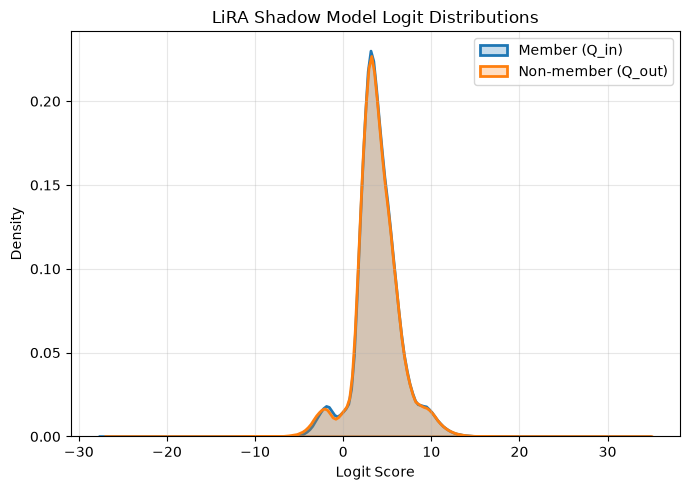

In [354]:
# Step -12 Visualize the Two Gaussian Distributions

plt.figure(figsize=(7,5))

sns.kdeplot(
    Q_in,
    label="Member (Q_in)",
    fill=True,
    linewidth=2
)

sns.kdeplot(
    Q_out,
    label="Non-member (Q_out)",
    fill=True,
    linewidth=2
)

plt.xlabel("Logit Score")
plt.ylabel("Density")
plt.title("LiRA Shadow Model Logit Distributions")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [355]:
# ============================================================
# LiRA Step 13: Compute Target Model Logits
# ============================================================

# Members (original training patients)

target_train_prob = mlp.predict_proba(
    X_train_scaled_original
)

# Non-members (original test patients)

target_test_prob = mlp.predict_proba(
    X_test_scaled
)

# Probability assigned to the true class

target_train_true_prob = target_train_prob[
    np.arange(len(y_train)),
    y_train
]

target_test_true_prob = target_test_prob[
    np.arange(len(y_test)),
    y_test
]

# Convert probabilities to logits

eps = 1e-15

target_train_true_prob = np.clip(
    target_train_true_prob,
    eps,
    1-eps
)

target_test_true_prob = np.clip(
    target_test_true_prob,
    eps,
    1-eps
)

target_member_logits = np.log(
    target_train_true_prob /
    (1-target_train_true_prob)
)

target_nonmember_logits = np.log(
    target_test_true_prob /
    (1-target_test_true_prob)
)

print("Target member logits    :", target_member_logits.shape)
print("Target non-member logits:", target_nonmember_logits.shape)

print("\nMember mean :", np.mean(target_member_logits))
print("Non-member mean :", np.mean(target_nonmember_logits))

Target member logits    : (160647,)
Target non-member logits: (40177,)

Member mean : 4.327252283870348
Non-member mean : 4.220791447037473


In [346]:
print("Number of shadow models:", len(all_shadow_in_logits))
print("Number of shadow OUT sets:", len(all_shadow_out_logits))

Number of shadow models: 10
Number of shadow OUT sets: 10


In [356]:
# ============================================================
# LiRA Step 14: Compute Log-Likelihood Ratios
# ============================================================

# ---------- Members ----------

from scipy.stats import norm

log_p_in_member = norm.logpdf(
    target_member_logits,
    loc=mu_in,
    scale=sigma_in
)

log_p_out_member = norm.logpdf(
    target_member_logits,
    loc=mu_out,
    scale=sigma_out
)

member_lira_scores = (
    log_p_in_member -
    log_p_out_member
)

# ---------- Non-members ----------

log_p_in_nonmember = norm.logpdf(
    target_nonmember_logits,
    loc=mu_in,
    scale=sigma_in
)

log_p_out_nonmember = norm.logpdf(
    target_nonmember_logits,
    loc=mu_out,
    scale=sigma_out
)

nonmember_lira_scores = (
    log_p_in_nonmember -
    log_p_out_nonmember
)

print("Member scores:", member_lira_scores.shape)
print("Non-member scores:", nonmember_lira_scores.shape)

Member scores: (160647,)
Non-member scores: (40177,)


In [357]:
# ============================================================
# LiRA Step 15: Create Attack Dataset
# ============================================================

lira_scores = np.concatenate([
    member_lira_scores,
    nonmember_lira_scores
])

lira_labels = np.concatenate([
    np.ones(len(member_lira_scores)),
    np.zeros(len(nonmember_lira_scores))
])

print(lira_scores.shape)
print(lira_labels.shape)

(200824,)
(200824,)


In [358]:
# ============================================================
# LiRA Step 16: Compute LiRA Attack AUC
# ============================================================

from sklearn.metrics import roc_auc_score

lira_auc = roc_auc_score(
    lira_labels,
    lira_scores
)

print(
    f"LiRA Attack AUC: {lira_auc:.3f}"
)

LiRA Attack AUC: 0.507


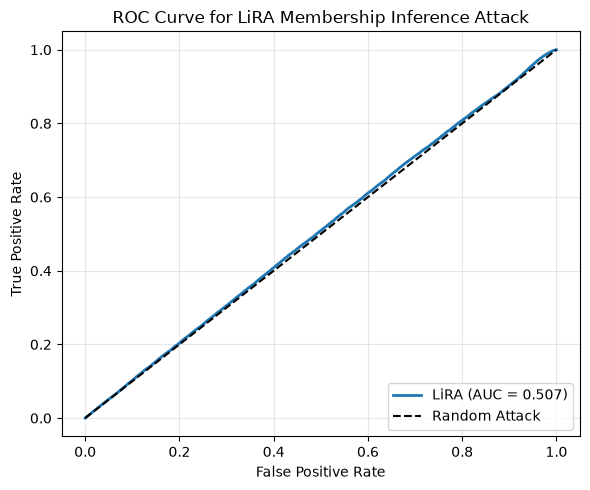

In [360]:
# ============================================================
# LiRA Step 17: ROC Curve
# ============================================================

from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    lira_labels,
    lira_scores
)

plt.figure(figsize=(6,5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"LiRA (AUC = {lira_auc:.3f})"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Random Attack"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for LiRA Membership Inference Attack")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# LiRA Step 18: Best Threshold
# ============================================================

from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(
    lira_labels,
    lira_scores
)

f1_scores = (
    2 * precision * recall /
    (precision + recall + 1e-10)
)

best_threshold = thresholds[
    np.argmax(f1_scores[:-1])
]

print(
    f"Best Threshold: {best_threshold:.4f}"
)

In [130]:
# ============================================================
# LiRA Step 19: Classification Report
# ============================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

decision_threshold = -0.05

lira_pred = (
    lira_scores >= decision_threshold
    #lira_scores >= -0.05
).astype(int)

print(
    classification_report(
        lira_labels,
        lira_pred,
        digits=4
    )
)

print(
    confusion_matrix(
        lira_labels,
        lira_pred
    )
)

              precision    recall  f1-score   support

         0.0     0.2033    0.1223    0.1527     40177
         1.0     0.8004    0.8801    0.8383    160647

    accuracy                         0.7285    200824
   macro avg     0.5018    0.5012    0.4955    200824
weighted avg     0.6809    0.7285    0.7012    200824

[[  4915  35262]
 [ 19264 141383]]


# 2.1 Applying Random Forest

Mortality Prediction Evaluation by RF

In [76]:
from sklearn.ensemble import RandomForestClassifier

rf_smote = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    #class_weight='balanced',
    n_jobs=-1
)

rf_smote.fit(
    X_train_smote,
    y_train_smote
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [ ]:
# Mortality Prediction Evaluation (Random Forest)

In [77]:
y_prob_rf = rf_smote.predict_proba(X_test)[:, 1]

In [79]:
precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_prob_rf
)

f1_scores = 2 * precision * recall / (precision + recall + 1e-10)

best_idx = np.argmax(f1_scores)

print("Best threshold:", thresholds[best_idx])
print("Best F1:", f1_scores[best_idx])
print("Precision:", precision[best_idx])
print("Recall:", recall[best_idx])

Best threshold: 0.27
Best F1: 0.25708635459738677
Precision: 0.24872448979591838
Recall: 0.2660300136425648


In [80]:
threshold = 0.27

y_pred_rf = (y_prob_rf >= threshold).astype(int)

print(
    classification_report(
        y_test,
        y_pred_rf,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9573    0.9535    0.9554     37978
           1     0.2487    0.2660    0.2571      2199

    accuracy                         0.9158     40177
   macro avg     0.6030    0.6098    0.6062     40177
weighted avg     0.9185    0.9158    0.9172     40177



Random Forest Utility AUC: 0.761


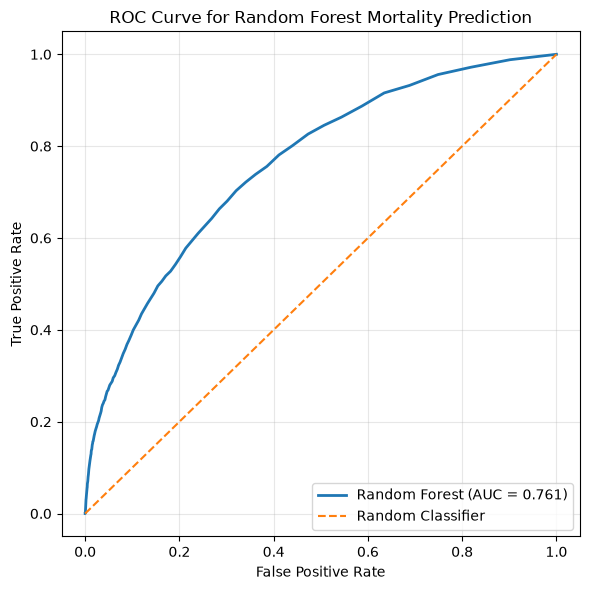

In [81]:
# Compute ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_rf
)

# Compute Utility AUC
utility_auc_rf = roc_auc_score(
    y_test,
    y_prob_rf
)

print(
    f"Random Forest Utility AUC: {utility_auc_rf:.3f}"
)

# Plot ROC curve
plt.figure(figsize=(6, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Random Forest (AUC = {utility_auc_rf:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Random Forest Mortality Prediction")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 2.2.1 Loss Based Membership Inference Attack on Random Forest (SMOTE-Expanded Training Set)

In [143]:
# Compute per-sample loss (Random Forest)

eps = 1e-15

# Members
train_prob_rf = rf_smote.predict_proba(
    X_train_smote
)

train_true_prob_rf = (
    train_prob_rf[
        np.arange(len(y_train_smote)),
        y_train_smote
    ]
)

train_loss_rf = -np.log(
    np.clip(
        train_true_prob_rf,
        eps,
        1 - eps
    )
)

# Non-members
test_prob_rf = rf_smote.predict_proba(
    X_test
)

test_true_prob_rf = (
    test_prob_rf[
        np.arange(len(y_test)),
        y_test
    ]
)

test_loss_rf = -np.log(
    np.clip(
        test_true_prob_rf,
        eps,
        1 - eps
    )
)

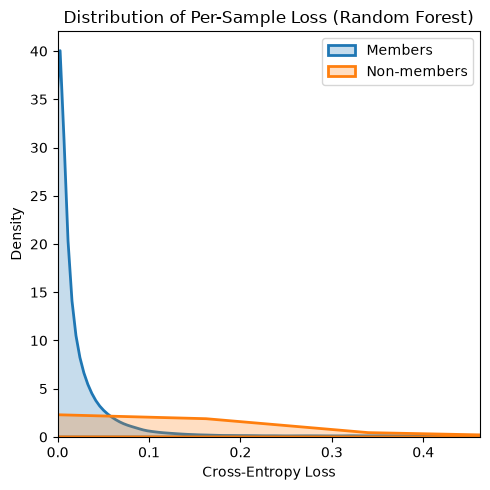

In [144]:
plt.figure(figsize=(5, 5))

sns.kdeplot(
    train_loss_rf,
    fill=True,
    linewidth=2,
    label="Members"
)

sns.kdeplot(
    test_loss_rf,
    fill=True,
    linewidth=2,
    label="Non-members"
)

# Zoom to the main distribution
upper = np.percentile(
    np.concatenate([train_loss_rf, test_loss_rf]),
    99
)

plt.xlim(0, upper)

plt.xlabel("Cross-Entropy Loss")
plt.ylabel("Density")
plt.title("Distribution of Per-Sample Loss (Random Forest)")
plt.legend()

plt.tight_layout()
plt.show()

Loss Based Membership Inference Attack AUC Random Forest (Smote data): 0.759


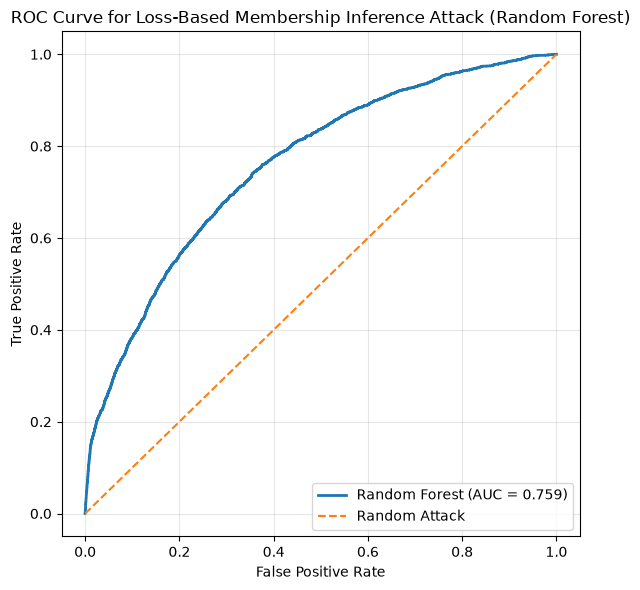

In [145]:
# Attack scores

attack_scores_rf = np.concatenate([
    -train_loss_rf,
    -test_loss_rf
])

attack_labels_rf = np.concatenate([
    np.ones(len(train_loss_rf)),
    np.zeros(len(test_loss_rf))
])

# Attack AUC

mia_auc_rf = roc_auc_score(
    attack_labels_rf,
    attack_scores_rf
)


print(
    f"Loss Based Membership Inference Attack AUC Random Forest (Smote data): {mia_auc_rf:.3f}"
)

# Plot ROC Curve
plt.figure(figsize=(6,6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Random Forest (AUC = {mia_auc_rf:.3f})"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    linewidth=1.5,
    label="Random Attack"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Loss-Based Membership Inference Attack (Random Forest)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 2.2.2 Loss-Based Membership Inference Attack on Random Forest (Original member training set)

In [147]:
# Compute per-sample loss (Random Forest)

eps = 1e-15

# --------------------------------------------------------
# Members: ORIGINAL training records only
# --------------------------------------------------------

train_prob_rf = rf_smote.predict_proba(
    X_train
)

train_true_prob_rf = train_prob_rf[
    np.arange(len(y_train)),
    y_train
]

train_loss_rf = -np.log(
    np.clip(
        train_true_prob_rf,
        eps,
        1 - eps
    )
)

# --------------------------------------------------------
# Non-members: ORIGINAL held-out test records
# --------------------------------------------------------

test_prob_rf = rf_smote.predict_proba(
    X_test
)

test_true_prob_rf = test_prob_rf[
    np.arange(len(y_test)),
    y_test
]

test_loss_rf = -np.log(
    np.clip(
        test_true_prob_rf,
        eps,
        1 - eps
    )
)

Loss Based Membership Inference Attack AUC Random Forest (original member data): 0.674


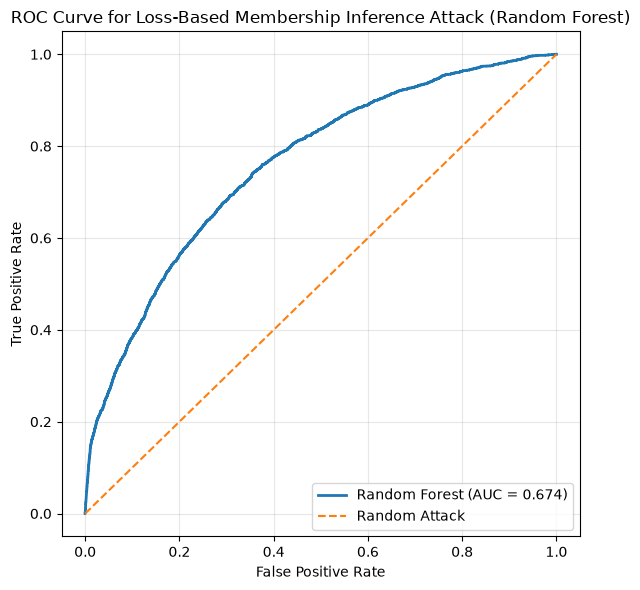

In [169]:
# Attack scores

attack_scores_rf = np.concatenate([
    -train_loss_rf,
    -test_loss_rf
])

attack_labels_rf = np.concatenate([
    np.ones(len(train_loss_rf)),
    np.zeros(len(test_loss_rf))
])

# Attack AUC

mia_auc_rf = roc_auc_score(
    attack_labels_rf,
    attack_scores_rf
)


print(
    f"Loss Based Membership Inference Attack AUC Random Forest (original member data): {mia_auc_rf:.3f}"
)

# Plot ROC Curve
plt.figure(figsize=(6,6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Random Forest (AUC = {mia_auc_rf:.3f})"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    linewidth=1.5,
    label="Random Attack"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Loss-Based Membership Inference Attack (Random Forest)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [148]:
print("Utility AUC:", utility_auc_rf)
print("Attack AUC:", mia_auc_rf)

Utility AUC: 0.7606805150901012
Attack AUC: 0.7593890449470285


In [149]:
print("Member mean:", train_loss_rf.mean())
print("Non-member mean:", test_loss_rf.mean())

Member mean: 0.042466589076767404
Non-member mean: 0.21321409619293338


In [150]:
train_prob_rf = rf_smote.predict_proba(X_train_smote)[:, 1]
test_prob_rf = rf_smote.predict_proba(X_test)[:, 1]

print("Training ROC-AUC:",
      roc_auc_score(y_train_smote, train_prob_rf))

print("Test ROC-AUC:",
      roc_auc_score(y_test, test_prob_rf))

Training ROC-AUC: 0.9999999999783413
Test ROC-AUC: 0.7606805150901012


# 3.1 Applying XGBOOST Model 

In [152]:
pip install xgboost


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Mortality Prediction Evaluation by XGBOOST

In [153]:
from xgboost import XGBClassifier

xgb_smote = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

xgb_smote.fit(
    X_train_smote,
    y_train_smote
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [154]:
# Predicted labels
y_pred_xgb = xgb_smote.predict(
    X_test
)

# Predicted probabilities
y_prob_xgb = xgb_smote.predict_proba(
    X_test
)[:, 1]

# Utility AUC
utility_auc_xgb = roc_auc_score(
    y_test,
    y_prob_xgb
)

In [155]:
precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_prob_xgb
)

f1_scores = 2 * precision * recall / (
    precision + recall + 1e-10
)

best_idx = np.argmax(f1_scores[:-1])

best_threshold_xgb = thresholds[best_idx]

print(f"Best Threshold (XGBoost): {best_threshold_xgb:.3f}")
print(f"Best F1-score: {f1_scores[best_idx]:.4f}")

Best Threshold (XGBoost): 0.304
Best F1-score: 0.2560


In [156]:
threshold = 0.304

y_pred_xgb = (y_prob_xgb >= threshold).astype(int)

print(
    classification_report(
        y_test,
        y_pred_xgb,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9588    0.9374    0.9480     37978
           1     0.2195    0.3042    0.2550      2199

    accuracy                         0.9027     40177
   macro avg     0.5891    0.6208    0.6015     40177
weighted avg     0.9183    0.9027    0.9100     40177



In [157]:
utility_auc_xgb = roc_auc_score(
    y_test,
    y_prob_xgb
)

print(
    f"XGBoost Utility AUC: {utility_auc_xgb:.3f}"
)

XGBoost Utility AUC: 0.759


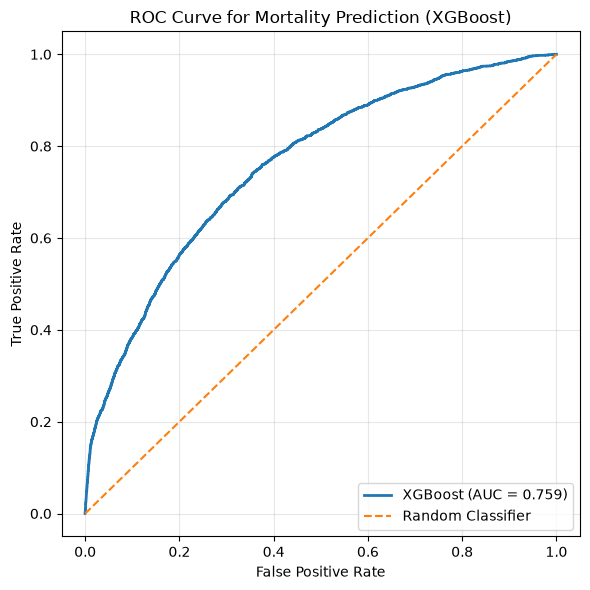

In [95]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_xgb
)

plt.figure(figsize=(6,6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"XGBoost (AUC = {utility_auc_xgb:.3f})"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Mortality Prediction (XGBoost)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 3.2.1 Loss Based Membership Inference Attack on XGBOOST (SMOTE-Expanded Training Set)

In [170]:
# Compute per-sample loss (XGBoost)

eps = 1e-15

# Members
train_prob_xgb = xgb_smote.predict_proba(
    X_train_smote
)

train_true_prob_xgb = (
    train_prob_xgb[
        np.arange(len(y_train_smote)),
        y_train_smote
    ]
)

train_loss_xgb = -np.log(
    np.clip(
        train_true_prob_xgb,
        eps,
        1 - eps
    )
)

# Non-members
test_prob_xgb = xgb_smote.predict_proba(
    X_test
)

test_true_prob_xgb = (
    test_prob_xgb[
        np.arange(len(y_test)),
        y_test
    ]
)

test_loss_xgb = -np.log(
    np.clip(
        test_true_prob_xgb,
        eps,
        1 - eps
    )
)

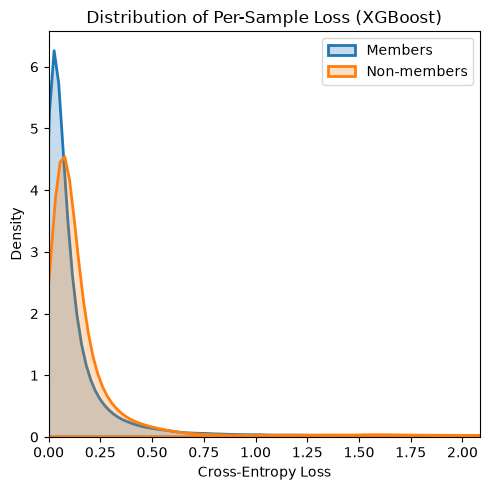

In [171]:
plt.figure(figsize=(5,5))

sns.kdeplot(
    train_loss_xgb,
    fill=True,
    linewidth=2,
    label="Members"
)

sns.kdeplot(
    test_loss_xgb,
    fill=True,
    linewidth=2,
    label="Non-members"
)

# Zoom into the main distribution
upper = np.percentile(
    np.concatenate([
        train_loss_xgb,
        test_loss_xgb
    ]),
    99
)

plt.xlim(0, upper)

plt.xlabel("Cross-Entropy Loss")
plt.ylabel("Density")
plt.title("Distribution of Per-Sample Loss (XGBoost)")
plt.legend()

plt.tight_layout()
plt.show()

In [172]:
# Attack scores

attack_scores_xgb = np.concatenate([
    -train_loss_xgb,
    -test_loss_xgb
])

attack_labels_xgb = np.concatenate([
    np.ones(len(train_loss_xgb)),
    np.zeros(len(test_loss_xgb))
])

mia_auc_xgb = roc_auc_score(
    attack_labels_xgb,
    attack_scores_xgb
)

print(
    f"Loss Based Membership Inference Attack AUC XGBoost (Smote Data): {mia_auc_xgb:.3f}"
)

Loss Based Membership Inference Attack AUC XGBoost (Smote Data): 0.627


# 3.2.2 Loss Based Membership Inference Attack on XGBOOST (Original Member training Set)

In [173]:
# ============================================================
# Compute per-sample loss — XGBoost
# ============================================================

eps = 1e-15

# ------------------------------------------------------------
# Members: ORIGINAL training records only
# ------------------------------------------------------------

train_prob_xgb = xgb_smote.predict_proba(
    X_train
)

train_true_prob_xgb = train_prob_xgb[
    np.arange(len(y_train)),
    y_train
]

train_loss_xgb = -np.log(
    np.clip(
        train_true_prob_xgb,
        eps,
        1 - eps
    )
)

# ------------------------------------------------------------
# Non-members: ORIGINAL held-out test records
# ------------------------------------------------------------

test_prob_xgb = xgb_smote.predict_proba(
    X_test
)

test_true_prob_xgb = test_prob_xgb[
    np.arange(len(y_test)),
    y_test
]

test_loss_xgb = -np.log(
    np.clip(
        test_true_prob_xgb,
        eps,
        1 - eps
    )
)

# ------------------------------------------------------------
# Check sizes
# ------------------------------------------------------------

print("Number of member samples:", len(train_loss_xgb))
print("Number of non-member samples:", len(test_loss_xgb))

Number of member samples: 160647
Number of non-member samples: 40177


In [174]:
# Attack scores

attack_scores_xgb = np.concatenate([
    -train_loss_xgb,
    -test_loss_xgb
])

attack_labels_xgb = np.concatenate([
    np.ones(len(train_loss_xgb)),
    np.zeros(len(test_loss_xgb))
])

In [175]:
mia_auc_xgb = roc_auc_score(
    attack_labels_xgb,
    attack_scores_xgb
)

print(
    f"Loss Based Membership Inference Attack AUC XGBoost (original member data): {mia_auc_xgb:.3f}"
)

Loss Based Membership Inference Attack AUC XGBoost (original member data): 0.503


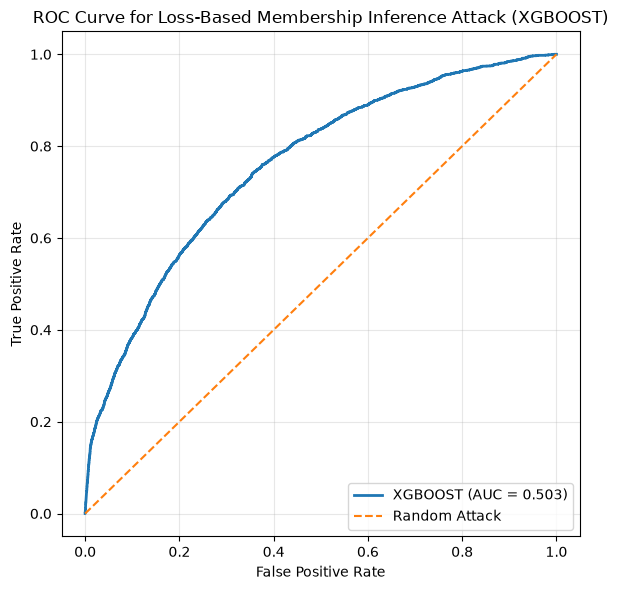

In [103]:
# Plot ROC Curve
plt.figure(figsize=(6,6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"XGBOOST (AUC = {mia_auc_xgb:.3f})"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    linewidth=1.5,
    label="Random Attack"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Loss-Based Membership Inference Attack (XGBOOST)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Differential Privacy

In [162]:
pip install opacus


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# 4.1: Apply Differential Privacy on MLP SMOTE

Can Differential Privacy mitigate the privacy leakage introduced by SMOTE?

How does class imbalance mitigation using SMOTE affect membership inference vulnerability in ICU mortality prediction models, and can differential privacy reduce the resulting privacy risk without severely degrading predictive performance?

In [107]:
# Using Opacus

# Convert data to tensors

import torch

X_train_tensor = torch.tensor(
    X_train_smote_scaled,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_smote.values,
    dtype=torch.long
)

X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test.values,
    dtype=torch.long
)


In [108]:
# Create Dataset

from torch.utils.data import (
    TensorDataset,
    DataLoader
)

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

In [110]:
# Define MLP

import torch.nn as nn

class MLP(nn.Module):

    def __init__(self, input_dim):

        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.net(x)

In [111]:
# initialize model
model = MLP(
    X_train_tensor.shape[1]
)

In [112]:
# optimizer

import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

DP-SGD process is:

Compute gradients
       ->
Clip gradients
       ->
Add noise
       ->
Update model


In [ ]:
# Attach Opacus

In [113]:
from opacus import PrivacyEngine

privacy_engine = PrivacyEngine()

model, optimizer, train_loader = (
    privacy_engine.make_private(
        module=model,
        optimizer=optimizer,
        data_loader=train_loader,
        noise_multiplier=1.0,
        #noise_multiplier=0.7,
        max_grad_norm=1.0
    )
)

/usr/local/lib/python3.11/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


In [114]:
# Train

criterion = nn.CrossEntropyLoss()

epochs = 30

for epoch in range(epochs):

    model.train()

    running_loss = 0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(
            outputs,
            y_batch
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch {epoch+1}:",
        running_loss
    )

/tmp/ipykernel_599357/2484103986.py:24: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  loss.backward()
/usr/local/lib/python3.11/dist-packages/torch/autograd/graph.py:882: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 34: CUDA driver is a stub library (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 1: 345.83005411177874
Epoch 2: 342.5923656709492
Epoch 3: 357.0400477088988
Epoch 4: 367.20531785301864
Epoch 5: 374.5677718091756
Epoch 6: 374.4454402476549
Epoch 7: 361.5692507252097
Epoch 8: 350.94917483255267
Epoch 9: 352.1563045363873
Epoch 10: 352.5436085835099
Epoch 11: 353.27368864044547
Epoch 12: 339.03838047012687
Epoch 13: 365.8317016027868
Epoch 14: 355.2485262416303
Epoch 15: 342.24883126467466
Epoch 16: 357.5003172121942
Epoch 17: 351.84414806216955
Epoch 18: 343.171715606004
Epoch 19: 327.7979800403118
Epoch 20: 335.5621359683573
Epoch 21: 336.58342203870416
Epoch 22: 356.0054248627275
Epoch 23: 348.88630217686296
Epoch 24: 357.40862613357604
Epoch 25: 381.4066392760724
Epoch 26: 381.038389287889
Epoch 27: 394.84346069023013
Epoch 28: 375.00422752276063
Epoch 29: 376.942719258368
Epoch 30: 385.1696199774742


In [ ]:
# Privacy Budget

In [115]:
epsilon = privacy_engine.get_epsilon(
    delta=1e-5
)

print(
    "Privacy epsilon:",
    epsilon
)

Privacy epsilon: 0.7842101686554596


In [116]:
import torch
import numpy as np

model.eval()

with torch.no_grad():

    logits_mlp_dp = model(
        X_test_tensor
    )

    probs_mlp_dp = torch.softmax(
        logits_mlp_dp,
        dim=1
    )

    y_prob_mlp_dp = probs_mlp_dp[:, 1].cpu().numpy()


y_pred_mlp_dp = (
    y_prob_mlp_dp >= 0.5
).astype(int)

print(
    classification_report(
        y_test,
        y_pred_mlp_dp,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9501    0.9860    0.9677     37978
           1     0.3059    0.1064    0.1579      2199

    accuracy                         0.9379     40177
   macro avg     0.6280    0.5462    0.5628     40177
weighted avg     0.9149    0.9379    0.9234     40177



In [117]:
utility_auc_dp = roc_auc_score(
    y_test,
    y_prob_mlp_dp
)

print(
    f"DP-MLP Utility AUC: {utility_auc_dp:.3f}"
)

DP-MLP Utility AUC: 0.726


# 4.1.2 Loss Based Attack on MLP After DP (Smote Data)

In [167]:
model.eval()

# Members
with torch.no_grad():

    train_logits_mlp_dp = model(
        X_train_tensor
    )

    train_probs_mlp_dp = torch.softmax(
        train_logits_mlp_dp,
        dim=1
    ).cpu().numpy()

# Non-members
with torch.no_grad():

    test_logits_mlp_dp = model(
        X_test_tensor
    )

    test_probs_mlp_dp = torch.softmax(
        test_logits_mlp_dp,
        dim=1
    ).cpu().numpy()

# Compute true-class probabilities

train_true_prob_mlp_dp = (
    train_probs_mlp_dp[
        np.arange(len(y_train_tensor)),
        y_train_tensor.numpy()
    ]
)

test_true_prob_mlp_dp = (
    test_probs_mlp_dp[
        np.arange(len(y_test_tensor)),
        y_test_tensor.numpy()
    ]
)

# Compute per-sample loss

eps = 1e-15

train_loss_mlp_dp = -np.log(
    np.clip(
        train_true_prob_mlp_dp,
        eps,
        1 - eps
    )
)

test_loss_mlp_dp = -np.log(
    np.clip(
        test_true_prob_mlp_dp,
        eps,
        1 - eps
    )
)

# Attack scores

attack_scores_mlp_dp = np.concatenate([
    -train_loss_mlp_dp,
    -test_loss_mlp_dp
])

attack_labels_mlp_dp = np.concatenate([
    np.ones(len(train_loss_mlp_dp)),
    np.zeros(len(test_loss_mlp_dp))
])

# Attack AUC

mia_auc_mlp_dp = roc_auc_score(
    attack_labels_mlp_dp,
    attack_scores_mlp_dp
)

print(
    f"Loss-Based Membership Inference Attack AUC (DP-MLP): {mia_auc_mlp_dp:.3f}"
)

Loss-Based Membership Inference Attack AUC (DP-MLP): 0.692


In [168]:
# print(X_train_scaled_original.shape)
# print(X_train.shape)

# print(X_test_scaled.shape)
# print(X_test.shape)

In [124]:
# # ============================================================
# # Loss-Based Membership Inference Attack — DP-MLP
# # ============================================================

# model.eval()

# # ------------------------------------------------------------
# # Prepare ORIGINAL training and test tensors
# # ------------------------------------------------------------

# X_train_tensor_original = torch.tensor(
#     X_train_scaled_original,
#     dtype=torch.float32
# )

# y_train_tensor_original = torch.tensor(
#     y_train.values if hasattr(y_train, "values") else y_train,
#     dtype=torch.long
# )

# X_test_tensor_original = torch.tensor(
#     X_test_scaled,
#     dtype=torch.float32
# )

# y_test_tensor_original = torch.tensor(
#     y_test.values if hasattr(y_test, "values") else y_test,
#     dtype=torch.long
# )

# # ------------------------------------------------------------
# # Members: ORIGINAL training records
# # ------------------------------------------------------------

# with torch.no_grad():

#     train_logits_mlp_dp = model(
#         X_train_tensor_original
#     )

#     train_probs_mlp_dp = torch.softmax(
#         train_logits_mlp_dp,
#         dim=1
#     ).cpu().numpy()

# # ------------------------------------------------------------
# # Non-members: ORIGINAL held-out test records
# # ------------------------------------------------------------

# with torch.no_grad():

#     test_logits_mlp_dp = model(
#         X_test_tensor_original
#     )

#     test_probs_mlp_dp = torch.softmax(
#         test_logits_mlp_dp,
#         dim=1
#     ).cpu().numpy()

# # ------------------------------------------------------------
# # True-class probabilities
# # ------------------------------------------------------------

# train_true_prob_mlp_dp = train_probs_mlp_dp[
#     np.arange(len(y_train_tensor_original)),
#     y_train_tensor_original.numpy()
# ]

# test_true_prob_mlp_dp = test_probs_mlp_dp[
#     np.arange(len(y_test_tensor_original)),
#     y_test_tensor_original.numpy()
# ]

# # ------------------------------------------------------------
# # Per-sample loss
# # ------------------------------------------------------------

# eps = 1e-15

# train_loss_mlp_dp = -np.log(
#     np.clip(
#         train_true_prob_mlp_dp,
#         eps,
#         1 - eps
#     )
# )

# test_loss_mlp_dp = -np.log(
#     np.clip(
#         test_true_prob_mlp_dp,
#         eps,
#         1 - eps
#     )
# )

# # ------------------------------------------------------------
# # Attack scores
# # Higher score = stronger membership evidence
# # ------------------------------------------------------------

# attack_scores_mlp_dp = np.concatenate([
#     -train_loss_mlp_dp,
#     -test_loss_mlp_dp
# ])

# attack_labels_mlp_dp = np.concatenate([
#     np.ones(len(train_loss_mlp_dp)),
#     np.zeros(len(test_loss_mlp_dp))
# ])

# # ------------------------------------------------------------
# # ROC-AUC
# # ------------------------------------------------------------

# mia_auc_mlp_dp = roc_auc_score(
#     attack_labels_mlp_dp,
#     attack_scores_mlp_dp
# )

# print(
#     f"Loss-Based Membership Inference Attack AUC (DP-MLP): "
#     f"{mia_auc_mlp_dp:.3f}"
# )

# 4.2 Applying Input Perturbation (Laplace Noise) on XGBOOST ( Smote Training Data)

In [254]:
def add_laplace_noise(X, epsilon):

    sensitivity = 1.0

    scale = sensitivity / epsilon

    noise = np.random.laplace(
        loc=0,
        scale=scale,
        size=X.shape
    )

    return X + noise

In [260]:
X_train_smote_noisy = add_laplace_noise(
    X_train_smote,
    epsilon=3.5
)

In [261]:
from xgboost import XGBClassifier

xgb_dp = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

xgb_dp.fit(
    X_train_smote_noisy,
    y_train_smote
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [284]:
# Predict probabilities on the original test set
y_prob_xgb_dp = xgb_dp.predict_proba(
    X_test
)[:, 1]

# Compute utility AUC
utility_auc_xgb_dp = roc_auc_score(
    y_test,
    y_prob_xgb_dp
)

print(
    f"Noise-Perturbed XGBoost Utility AUC: {utility_auc_xgb_dp:.3f}"
)

Noise-Perturbed XGBoost Utility AUC: 0.736


In [263]:
y_pred_xgb_dp = (
    y_prob_xgb_dp >= 0.45
).astype(int)

print(
    classification_report(
        y_test,
        y_pred_xgb_dp,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9540    0.9734    0.9636     37978
           1     0.2925    0.1901    0.2304      2199

    accuracy                         0.9305     40177
   macro avg     0.6233    0.5817    0.5970     40177
weighted avg     0.9178    0.9305    0.9235     40177



# 4.2.2 Loss based membership inference attack on XGBOOST After Input Perturbation

In [285]:
# Get train and test probabilities

train_prob_xgb_dp = xgb_dp.predict_proba(
    X_train_smote_noisy
)

test_prob_xgb_dp = xgb_dp.predict_proba(
    X_test
)

# Compute true-class probabilities

train_true_prob_xgb_dp = (
    train_prob_xgb_dp[
        np.arange(len(y_train_smote)),
        y_train_smote
    ]
)

test_true_prob_xgb_dp = (
    test_prob_xgb_dp[
        np.arange(len(y_test)),
        y_test
    ]
)

# Compute per-sample loss

eps = 1e-15

train_loss_xgb_dp = -np.log(
    np.clip(
        train_true_prob_xgb_dp,
        eps,
        1 - eps
    )
)

test_loss_xgb_dp = -np.log(
    np.clip(
        test_true_prob_xgb_dp,
        eps,
        1 - eps
    )
)

# Attack scores

attack_scores_xgb_dp = np.concatenate([
    -train_loss_xgb_dp,
    -test_loss_xgb_dp
])

attack_labels_xgb_dp = np.concatenate([
    np.ones(len(train_loss_xgb_dp)),
    np.zeros(len(test_loss_xgb_dp))
])

# Attack AUC

mia_auc_xgb_dp = roc_auc_score(
    attack_labels_xgb_dp,
    attack_scores_xgb_dp
)

print(
    f"Loss-Based Membership Inference Attack AUC (DP-XGBoost): {mia_auc_xgb_dp:.3f}"
)

Loss-Based Membership Inference Attack AUC (DP-XGBoost): 0.362


Input Noise Perturbation on XGBOOST with range of Epsilons

In [367]:
# --------------------------------------------------
# Laplace input perturbation
# --------------------------------------------------

def add_laplace_noise(X, epsilon, sensitivity=1.0, random_state=None):

    rng = np.random.default_rng(random_state)

    scale = sensitivity/epsilon

    noise = rng.laplace(
        loc=0,
        scale=scale,
        size=X.shape
    )

    return X + noise


# --------------------------------------------------
# Epsilon values
# --------------------------------------------------

epsilon_values = np.arange(0.5, 6.1, 0.5)

results = []


# --------------------------------------------------
# Run experiment for each epsilon
# --------------------------------------------------

for i, epsilon in enumerate(epsilon_values):

    print(f"\nRunning epsilon = {epsilon:.1f}")

    # ----------------------------------------------
    # 1. Add Laplace noise to training data
    # ----------------------------------------------

    X_train_noisy = add_laplace_noise(
        X_train_smote,
        epsilon=epsilon,
        sensitivity=1.0,
        random_state=42 + i
    )


    # ----------------------------------------------
    # 2. Train XGBoost
    # ----------------------------------------------

    xgb_model = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=42
    )

    xgb_model.fit(
        X_train_noisy,
        y_train_smote
    )


    # ----------------------------------------------
    # 3. Utility evaluation on ORIGINAL test data
    # ----------------------------------------------

    y_prob = xgb_model.predict_proba(
        X_test
    )[:, 1]

    utility_auc = roc_auc_score(
        y_test,
        y_prob
    )


    # ----------------------------------------------
    # 4. Predictions for MIA
    # ----------------------------------------------

    train_prob = xgb_model.predict_proba(
        X_train_noisy
    )

    test_prob = xgb_model.predict_proba(
        X_test
    )


    # ----------------------------------------------
    # 5. True-class probabilities
    # ----------------------------------------------

    train_true_prob = train_prob[
        np.arange(len(y_train_smote)),
        y_train_smote
    ]

    test_true_prob = test_prob[
        np.arange(len(y_test)),
        y_test
    ]


    # ----------------------------------------------
    # 6. Per-sample loss
    # ----------------------------------------------

    eps_clip = 1e-15

    train_loss = -np.log(
        np.clip(
            train_true_prob,
            eps_clip,
            1 - eps_clip
        )
    )

    test_loss = -np.log(
        np.clip(
            test_true_prob,
            eps_clip,
            1 - eps_clip
        )
    )


    # ----------------------------------------------
    # 7. MIA attack scores
    # ----------------------------------------------

    attack_scores = np.concatenate([
        -train_loss,
        -test_loss
    ])

    attack_labels = np.concatenate([
        np.ones(len(train_loss)),
        np.zeros(len(test_loss))
    ])


    # ----------------------------------------------
    # 8. MIA AUC
    # ----------------------------------------------

    mia_auc = roc_auc_score(
        attack_labels,
        attack_scores
    )


    # Direction-adjusted distinguishability
    effective_mia_auc = max(
        mia_auc,
        1 - mia_auc
    )


    # ----------------------------------------------
    # 9. Store results
    # ----------------------------------------------

    results.append({
        "epsilon": epsilon,
        "laplace_scale": 1.0 / epsilon,
        "utility_auc": utility_auc,
        "mia_auc": mia_auc,
        "effective_mia_auc": effective_mia_auc
    })


    print(
        f"Utility AUC: {utility_auc:.3f} | "
        f"MIA AUC: {mia_auc:.3f} | "
        f"Effective MIA AUC: {effective_mia_auc:.3f}"
    )


# --------------------------------------------------
# Convert results to DataFrame
# --------------------------------------------------

results_df = pd.DataFrame(results)

print("\nFinal Results:")
print(results_df.round(3))


Running epsilon = 0.5
Utility AUC: 0.676 | MIA AUC: 0.384 | Effective MIA AUC: 0.616

Running epsilon = 1.0
Utility AUC: 0.698 | MIA AUC: 0.264 | Effective MIA AUC: 0.736

Running epsilon = 1.5
Utility AUC: 0.709 | MIA AUC: 0.251 | Effective MIA AUC: 0.749

Running epsilon = 2.0
Utility AUC: 0.719 | MIA AUC: 0.262 | Effective MIA AUC: 0.738

Running epsilon = 2.5
Utility AUC: 0.721 | MIA AUC: 0.288 | Effective MIA AUC: 0.712

Running epsilon = 3.0
Utility AUC: 0.727 | MIA AUC: 0.324 | Effective MIA AUC: 0.676

Running epsilon = 3.5
Utility AUC: 0.735 | MIA AUC: 0.361 | Effective MIA AUC: 0.639

Running epsilon = 4.0
Utility AUC: 0.737 | MIA AUC: 0.397 | Effective MIA AUC: 0.603

Running epsilon = 4.5
Utility AUC: 0.744 | MIA AUC: 0.437 | Effective MIA AUC: 0.563

Running epsilon = 5.0
Utility AUC: 0.747 | MIA AUC: 0.470 | Effective MIA AUC: 0.530

Running epsilon = 5.5
Utility AUC: 0.749 | MIA AUC: 0.498 | Effective MIA AUC: 0.502

Running epsilon = 6.0
Utility AUC: 0.752 | MIA AUC: 0

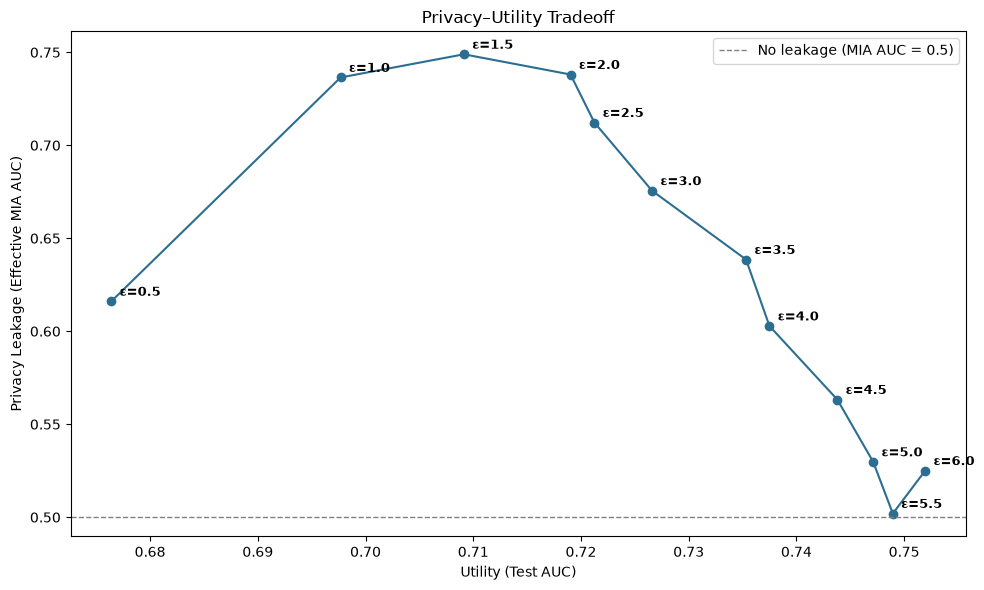

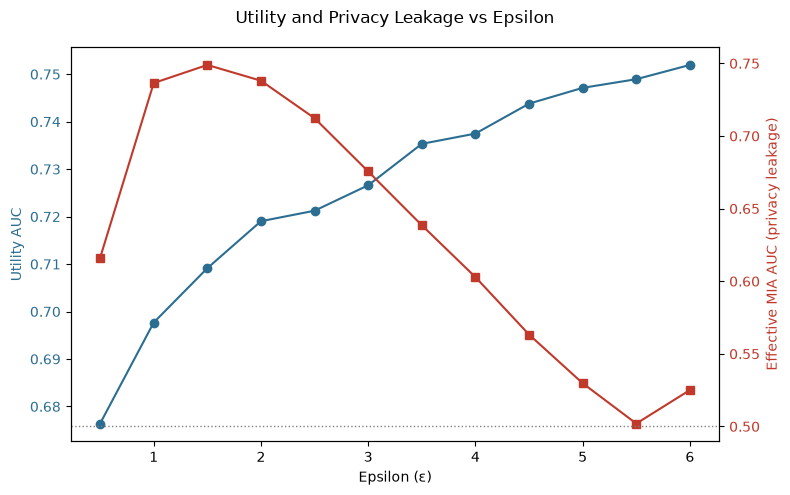

In [386]:
# --------------------------------------------------
# Plot 1: Tradeoff curve (utility vs privacy leakage)
# --------------------------------------------------
 
fig, ax = plt.subplots(figsize=(10, 6))
 
ax.plot(
    results_df["utility_auc"],
    results_df["effective_mia_auc"],
    marker="o",
    color="#2c6e91",
    linewidth=1.5
)
 
for _, row in results_df.iterrows():
    ax.annotate(
        f"ε={row['epsilon']:.1f}",
        (row["utility_auc"], row["effective_mia_auc"]),
        textcoords="offset points",
        xytext=(6, 4),
        fontsize=9,
        fontweight="bold",
    )
 
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="No leakage (MIA AUC = 0.5)")
ax.set_xlabel("Utility (Test AUC)")
ax.set_ylabel("Privacy Leakage (Effective MIA AUC)")
ax.set_title("Privacy–Utility Tradeoff")
ax.legend()
 
fig.tight_layout()
fig.savefig("tradeoff_curve.png", dpi=150)
 
 
# --------------------------------------------------
# Plot 2: Utility and privacy leakage vs epsilon
# --------------------------------------------------
 
fig, ax1 = plt.subplots(figsize=(8, 5))
 
ax1.plot(
    results_df["epsilon"],
    results_df["utility_auc"],
    marker="o",
    color="#2c6e91",
    label="Utility AUC"
)
ax1.set_xlabel("Epsilon (ε)")
ax1.set_ylabel("Utility AUC", color="#2c6e91")
ax1.tick_params(axis="y", labelcolor="#2c6e91")
 
ax2 = ax1.twinx()
ax2.plot(
    results_df["epsilon"],
    results_df["effective_mia_auc"],
    marker="s",
    color="#c0392b",
    label="Effective MIA AUC"
)
ax2.axhline(0.5, color="gray", linestyle=":", linewidth=1)
ax2.set_ylabel("Effective MIA AUC (privacy leakage)", color="#c0392b")
ax2.tick_params(axis="y", labelcolor="#c0392b")
 
fig.suptitle("Utility and Privacy Leakage vs Epsilon")
fig.tight_layout()
fig.savefig("vs_epsilon.png", dpi=150)
 
plt.show()

In [177]:
results = pd.DataFrame({
    "Experiment": [
        "MLP",
        "Random Forest",
        "XGBoost",
        "DP-MLP",
        "XGBoost + Laplace Noise (Optimized)"
    ],

    "Utility Training Data": [
        "SMOTE",
        "SMOTE",
        "SMOTE",
        "SMOTE + DP",
        "SMOTE + Input Perturbation"
    ],

    "Utility ROC-AUC": [
        0.765,
        0.761,
        0.759,
        0.716,
        0.749
    ],

    "Loss-Based MIA AUC (SMOTE-expanded members)": [
        0.730,
        0.759,
        0.627,
        0.694,
        0.502
    ],

    "Loss-Based MIA AUC (Original members)": [
        0.508,
        0.674,
        0.503,
        np.nan,
        np.nan
    ],

    "LiRA MIA AUC": [
        0.507,
        np.nan,
        np.nan,
        np.nan,
        np.nan
    ]
})

print(results.to_string(index=False))

                         Experiment      Utility Training Data  Utility ROC-AUC  Loss-Based MIA AUC (SMOTE-expanded members)  Loss-Based MIA AUC (Original members)  LiRA MIA AUC
                                MLP                      SMOTE            0.765                                        0.730                                  0.508         0.507
                      Random Forest                      SMOTE            0.761                                        0.759                                  0.674           NaN
                            XGBoost                      SMOTE            0.759                                        0.627                                  0.503           NaN
                             DP-MLP                 SMOTE + DP            0.716                                        0.694                                    NaN           NaN
XGBoost + Laplace Noise (Optimized) SMOTE + Input Perturbation            0.749                               